<h1 style="color:#6A0DAD;">Predicting 30-day hospital readmission in patients with diabetes</h1>

Exploration, statistical inference, model comparison and calibration

Author: Eugene Opoku Akosah, MSc Data Science, Aberystwyth University

Data: Diabetes 130-US hospitals for years 1999-2008 (Clore et al., 2014), first analysed by Strack et al. (2014).

How to use this notebook. Run the cells from top to bottom. Set `FAST = True` in the setup cell for a quick test on a subsample. A full run trains several models and many bootstrap resamples so allow time for it. The data are downloaded by your separate script, `data_download.py`, which also creates the project folders. This notebook does not download anything. It only reads `data/diabetic_data.csv`, saves the cleaned data in the `data` folder, writes every table to the `results` folder and every plot to the `figures` folder.

Contents

1. Research questions and hypotheses
2. Setup
3. Data loading
4. Data audit
5. Cleaning and feature engineering
6. Exploratory data analysis
7. Statistical inference
8. Patient-level data split
9. Preprocessing
10. Model training and tuning
11. Model evaluation
12. Recalibration
13. Interpretability
14. Subgroup analysis
15. Decision curve analysis
16. Leakage experiment
17. Findings and limitations
18. Reproducibility
19. References

<h2 style="color:#6A0DAD;">1. Research questions and hypotheses</h2>

| No | Research question | Approach |
|---|---|---|
| RQ1 | What is the 30-day readmission rate and how does it vary across patient and encounter characteristics | Exploratory analysis with confidence intervals |
| RQ2 | Which factors are associated with readmission after adjustment, and is HbA1c measurement associated with readmission as reported by Strack et al. (2014) | Chi-square and Mann-Whitney tests with false discovery rate control, multivariable logistic regression with patient-clustered standard errors, likelihood ratio test for interaction |
| RQ3 | How much does an encounter-level split overstate predictive performance compared with a patient-level split | Same models on both splits with clustered bootstrap intervals |
| RQ4 | Which model discriminates best and are the differences larger than sampling variability | Nine models, paired patient-clustered bootstrap for AUROC differences |
| RQ5 | Are predicted risks well calibrated and does recalibration help | Calibration slope, calibration-in-the-large, ECE, Brier score, Platt scaling and isotonic regression |
| RQ6 | Do discrimination and calibration differ by sex, age band and race | Subgroup metrics with bootstrap intervals |
| RQ7 | Would the model add net benefit over treating everyone or no one | Decision curve analysis |

Hypotheses are written before looking at results so that they can be tested and not fitted afterwards.

- H1 Prior inpatient visits show the strongest association with readmission among the measured factors.
- H2 After adjustment HbA1c measurement is associated with readmission and the association differs by primary diagnosis group as reported by Strack et al. (2014).
- H3 An encounter-level random split gives higher test AUROC than a patient-level split because the same patient appears in train and test.
- H4 Gradient boosting improves on regularised logistic regression only slightly, which is a common finding for tabular clinical data.
- H5 Uncalibrated tree ensembles and neural networks are less well calibrated than logistic regression and recalibration reduces the gap.

Statistical conventions. Significance level 0.05 two-sided. Families of tests are adjusted with the Benjamini-Hochberg procedure (Benjamini and Hochberg, 1995). With tens of thousands of patients tiny effects give tiny p-values so results are judged mainly by effect sizes and confidence intervals.

<h2 style="color:#6A0DAD;">2. Setup</h2>

In [ ]:
import json
import time
import copy
import platform
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats
import statsmodels
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.contingency_tables import Table2x2
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
import lightgbm as lgb
try:
    import shap
except ImportError:
    shap = None

warnings.filterwarnings("ignore")

SEED = 42
FAST = False          # True runs a quick test on a subsample
N_BOOT = 30 if FAST else 200

# The data are downloaded by your separate script. This notebook only locates the folder that holds
# the data folder it created and then reads the csv from there.
import os
PROJECT_DIR = Path("/home/eoa/Documents/PHD/Diabetics")   # where your download script writes data, results and figures
DATA_NAME = "diabetic_data.csv"


def find_project_dir():
    here = Path.cwd()
    candidates = ([Path(PROJECT_DIR)] if PROJECT_DIR else []) + [here, here.parent, Path("/home/eoa/Documents/PHD/Diabetics"), Path("/home/eoa/Documents/PHD"),
                                                                   Path.home() / "Documents" / "PHD", Path.home()]
    for folder in candidates:
        if (folder / "data" / DATA_NAME).exists():
            return folder
    # Fall back to a shallow search below the home folder, skipping hidden folders
    home = Path.home()
    for root, dirs, files in os.walk(home):
        dirs[:] = [d for d in dirs if not d.startswith(".")]
        if DATA_NAME in files and Path(root).name == "data":
            return Path(root).parent
        if len(Path(root).relative_to(home).parts) >= 5:
            dirs[:] = []
    raise FileNotFoundError(f"{DATA_NAME} was not found in a data folder. Run your download script first "
                            f"or set PROJECT_DIR to the folder that contains the data folder. Checked first: {PROJECT_DIR}")


BASE = find_project_dir()
DATA_DIR, RES_DIR, FIG_DIR = BASE / "data", BASE / "results", BASE / "figures"
for folder in (RES_DIR, FIG_DIR):          # normally created by the download script already
    folder.mkdir(parents=True, exist_ok=True)
FOLDERS = {"data": DATA_DIR, "results": RES_DIR, "figures": FIG_DIR}

plt.rcParams.update({"axes.titlecolor": "#6A0DAD", "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()


def savetable(frame, name):
    frame.to_csv(RES_DIR / f"{name}.csv", index=True)

print("Project folder:", BASE)
for _name, _path in FOLDERS.items():
    print(f"  {_name:8s} {_path}")

<h2 style="color:#6A0DAD;">3. Data loading</h2>

The data are read from `data/diabetic_data.csv`, which is created by your separate download script. This notebook does not download anything. If the file is missing run that script first. The project folder is `/home/eoa/Documents/PHD/Diabetics`, set as `PROJECT_DIR` in the setup cell. All tables, plots and the cleaned data are written inside it. If that folder is not found the notebook checks the current folder, its parent and then searches below the home folder. Change `PROJECT_DIR` if you move the project.

In [ ]:
DATA_FILE = DATA_DIR / DATA_NAME
raw = pd.read_csv(DATA_FILE, na_values="?", low_memory=False)
# Older pandas versions keep the string None so convert it explicitly
for col in ["max_glu_serum", "A1Cresult"]:
    raw[col] = raw[col].replace("None", np.nan)
print("Data file:", DATA_FILE)
print("Raw table:", raw.shape)
display(raw.head(3))

<h2 style="color:#6A0DAD;">4. Data audit</h2>

Before any modelling we check size, missing values, the outcome definition, duplicate rows and the repeat encounter structure. The last point matters because the same patient appears many times and this drives the splitting strategy.

,dtype,missing_pct,n_unique
weight,str,96.86,9
max_glu_serum,str,94.75,3
A1Cresult,str,83.28,3
medical_specialty,str,49.08,72
payer_code,str,39.56,17
race,str,2.23,5
diag_3,str,1.40,789
diag_2,str,0.35,748
diag_1,str,0.02,716
patient_nbr,int64,0.00,71518


Duplicate encounter ids: 0
Constant columns: ['examide', 'citoglipton']

Readmission values


,encounters,share
readmitted,,
NO,54864,0.5391
>30,35545,0.3493
<30,11357,0.1116


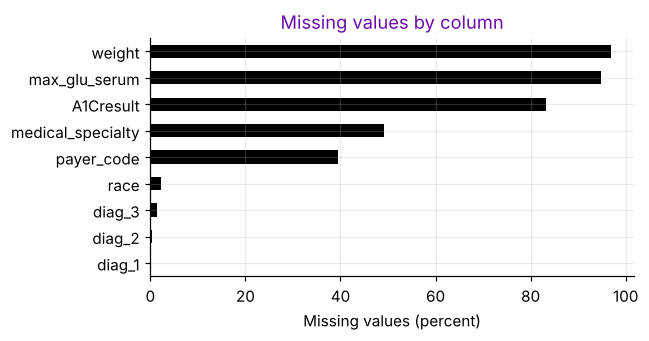

In [3]:
audit = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing_pct": (raw.isna().mean() * 100).round(2),
    "n_unique": raw.nunique(),
})
display(audit.sort_values("missing_pct", ascending=False).head(12))

print("Duplicate encounter ids:", raw["encounter_id"].duplicated().sum())
print("Constant columns:", [c for c in raw.columns if raw[c].nunique(dropna=False) <= 1])
print()
print("Readmission values")
display(raw["readmitted"].value_counts().to_frame("encounters").assign(share=lambda t: (t.encounters / t.encounters.sum()).round(4)))

miss = raw.isna().mean().sort_values(ascending=False)
miss = miss[miss > 0]
fig, ax = plt.subplots(figsize=(6, 3.2))
(miss * 100).sort_values().plot.barh(ax=ax, color="black")
ax.set_xlabel("Missing values (percent)")
ax.set_title("Missing values by column")
savefig("01_missingness")

**What this shows.** The table gives the share of missing values per column and the chart plots them. Weight is missing for 96.9 percent of encounters, the glucose test result for 94.8 percent, HbA1c for 83.3 percent, medical specialty for 49.1 percent and payer code for 39.6 percent. For the two test results a blank means the test was not done, which is clinically meaningful, so it is kept as its own level. Weight and payer code are too sparse to use. The outcome table shows that 11.2 percent of encounters ended in readmission within 30 days, 34.9 percent in readmission after 30 days and 53.9 percent in no readmission. There are no duplicate encounter ids and two constant columns, examide and citoglipton, which carry no information.

**Why it matters for the research.** The outcome is imbalanced at roughly one in nine, so plain accuracy would be misleading. The study therefore relies on AUROC, AUPRC and calibration.

Patients: 71,518   Encounters: 101,766
Patients with more than one encounter: 23.5%
Encounters belonging to those patients: 46.2%


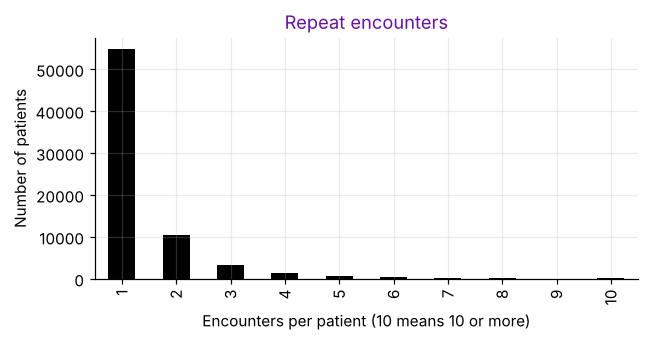

In [4]:
per_patient = raw.groupby("patient_nbr")["encounter_id"].count()
print(f"Patients: {per_patient.size:,}   Encounters: {len(raw):,}")
print(f"Patients with more than one encounter: {(per_patient > 1).mean():.1%}")
print(f"Encounters belonging to those patients: {per_patient[per_patient > 1].sum() / len(raw):.1%}")

fig, ax = plt.subplots(figsize=(6, 3.2))
per_patient.clip(upper=10).value_counts().sort_index().plot.bar(ax=ax, color="black")
ax.set_xlabel("Encounters per patient (10 means 10 or more)")
ax.set_ylabel("Number of patients")
ax.set_title("Repeat encounters")
savefig("02_encounters_per_patient")

**What this shows.** The chart counts the encounters of each patient. The file holds 71,518 patients and 101,766 encounters. A share of 23.5 percent of patients appear more than once and they account for 46.2 percent of all rows.

**Why it matters for the research.** Rows are not independent observations. Splitting rows at random could place the same patient in both training and test data, so the main analysis splits by patient and the statistical tests use one row per patient.

<h2 style="color:#6A0DAD;">5. Cleaning and feature engineering</h2>

Rules applied and the reason for each.

| Rule | Reason |
|---|---|
| Drop encounters ending in death or hospice (discharge codes 11, 13, 14, 19, 20, 21) | These patients cannot be readmitted so keeping them biases the outcome |
| Drop rows with invalid gender | A handful of rows only |
| Drop weight and payer code | Weight is about 97 percent missing and payer code is highly missing and a socioeconomic proxy |
| Group diagnosis codes into broad ICD-9 groups | The raw codes have hundreds of levels |
| Keep the 15 most common medical specialties and group the rest as Other | Stabilises estimates, uses frequency only and never the outcome |
| Treat a test that was not done as its own level | Not measuring HbA1c or glucose is informative and not simply missing |

Engineered features

| Feature | Definition |
|---|---|
| age_mid and age10 | Midpoint of the age bracket and the same value per 10 years |
| prior_visits_total | Outpatient plus emergency plus inpatient visits in the preceding year |
| any_prior_inpatient | One if there was at least one inpatient visit in the preceding year |
| a1c_tested and glucose_tested | One if HbA1c or serum glucose was measured |
| n_meds_active | Number of diabetes medications not recorded as No |
| n_med_changes | Number of medications whose dose went Up or Down |
| discharge_home | One if discharged to home |

All features are known by the time of discharge so predictions are made at discharge.

In [5]:
EXCLUDE_DISCHARGE = {11, 13, 14, 19, 20, 21}
MEDS = ["metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride", "acetohexamide",
        "glipizide", "glyburide", "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose", "miglitol",
        "troglitazone", "tolazamide", "insulin", "glyburide-metformin", "glipizide-metformin",
        "glimepiride-pioglitazone", "metformin-rosiglitazone", "metformin-pioglitazone"]
# examide and citoglipton are constant in this dataset so they are left out on purpose


def icd9_group(code):
    if pd.isna(code):
        return "Missing"
    s = str(code)
    if s.startswith(("V", "E")):
        return "External or other"
    try:
        v = float(s)
    except ValueError:
        return "Other"
    if 250 <= v < 251:
        return "Diabetes"
    if 390 <= v <= 459 or v == 785:
        return "Circulatory"
    if 460 <= v <= 519 or v == 786:
        return "Respiratory"
    if 520 <= v <= 579 or v == 787:
        return "Digestive"
    if 580 <= v <= 629 or v == 788:
        return "Genitourinary"
    if 140 <= v <= 239:
        return "Neoplasms"
    if 710 <= v <= 739:
        return "Musculoskeletal"
    if 800 <= v <= 999:
        return "Injury"
    return "Other"


def clean(raw):
    log = {"raw_encounters": int(len(raw)), "raw_patients": int(raw["patient_nbr"].nunique())}
    d = raw[~raw["discharge_disposition_id"].isin(EXCLUDE_DISCHARGE)].copy()
    log["excluded_died_or_hospice"] = int(len(raw) - len(d))
    n = len(d)
    d = d[d["gender"].isin(["Male", "Female"])].copy()
    log["excluded_invalid_gender"] = int(n - len(d))

    d["y"] = (d["readmitted"] == "<30").astype(int)
    d["age_mid"] = d["age"].str.extract(r"\[(\d+)-")[0].astype(float) + 5
    d["age10"] = d["age_mid"] / 10
    d["age_band"] = pd.cut(d["age_mid"], [0, 50, 70, 120], labels=["<50", "50-69", "70+"], right=False).astype(str)
    d["lab10"] = d["num_lab_procedures"] / 10
    d["discharge_home"] = (d["discharge_disposition_id"] == 1).astype(int)
    d["discharge_group"] = np.where(d["discharge_home"] == 1, "Home", "Other")
    d["prior_visits_total"] = d["number_outpatient"] + d["number_emergency"] + d["number_inpatient"]
    d["any_prior_inpatient"] = (d["number_inpatient"] > 0).astype(int)
    d["prior_inpatient_band"] = d["number_inpatient"].clip(upper=3).map({0: "0", 1: "1", 2: "2", 3: "3+"})
    d["los_band"] = pd.cut(d["time_in_hospital"], [0, 2, 4, 7, 14], labels=["1-2", "3-4", "5-7", "8-14"]).astype(str)
    d["a1c_tested"] = d["A1Cresult"].notna().astype(int)
    d["glucose_tested"] = d["max_glu_serum"].notna().astype(int)
    meds = [c for c in MEDS if c in d.columns]
    d["n_meds_active"] = (d[meds] != "No").sum(axis=1)
    d["n_med_changes"] = d[meds].isin(["Up", "Down"]).sum(axis=1)

    for c in ["diag_1", "diag_2", "diag_3"]:
        d[c + "_grp"] = d[c].map(icd9_group)
    d["medical_specialty"] = d["medical_specialty"].fillna("Missing")
    keep = d["medical_specialty"].value_counts().head(15).index
    d.loc[~d["medical_specialty"].isin(keep), "medical_specialty"] = "Other"
    d["max_glu_serum"] = d["max_glu_serum"].fillna("Not measured")
    d["A1Cresult"] = d["A1Cresult"].fillna("Not measured")

    cat = ["race", "gender", "admission_type_id", "discharge_disposition_id", "admission_source_id",
           "medical_specialty", "diag_1_grp", "diag_2_grp", "diag_3_grp", "max_glu_serum", "A1Cresult",
           "change", "diabetesMed"] + meds
    for c in cat:
        d[c] = d[c].fillna("Missing").astype(str)

    log["final_encounters"] = int(len(d))
    log["final_patients"] = int(d["patient_nbr"].nunique())
    log["readmit_30d_prevalence"] = round(float(d["y"].mean()), 4)
    return d.reset_index(drop=True), cat, meds, log


df, CAT_MODEL, MEDS_USED, cohort_log = clean(raw)

if FAST:
    rng = np.random.default_rng(SEED)
    patients = df["patient_nbr"].unique()
    keep = rng.choice(patients, size=int(0.3 * len(patients)), replace=False)
    df = df[df["patient_nbr"].isin(keep)].reset_index(drop=True)
    print("FAST mode, using", len(df), "encounters")

NUM_MODEL = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications", "number_outpatient",
             "number_emergency", "number_inpatient", "number_diagnoses", "age_mid", "prior_visits_total",
             "n_meds_active", "n_med_changes"]
FLAG_MODEL = ["a1c_tested", "glucose_tested", "any_prior_inpatient", "discharge_home"]
SIMPLE = ["number_inpatient", "number_emergency", "time_in_hospital", "number_diagnoses", "age_mid"]
FEATURES = NUM_MODEL + FLAG_MODEL + CAT_MODEL

cohort_log["analysis_encounters"] = int(len(df))
cohort_log["analysis_patients"] = int(df["patient_nbr"].nunique())
print(json.dumps(cohort_log, indent=2))
(RES_DIR / "cohort_flow.json").write_text(json.dumps(cohort_log, indent=2))
df.to_csv(DATA_DIR / "analysis_cohort.csv.gz", index=False)
print("Cleaned cohort saved to", DATA_DIR / "analysis_cohort.csv.gz")

{
  "raw_encounters": 101766,
  "raw_patients": 71518,
  "excluded_died_or_hospice": 2423,
  "excluded_invalid_gender": 3,
  "final_encounters": 99340,
  "final_patients": 69987,
  "readmit_30d_prevalence": 0.1139,
  "analysis_encounters": 99340,
  "analysis_patients": 69987
}


Cleaned cohort saved to /home/claude/real/data/analysis_cohort.csv.gz


**What this shows.** The cohort flow lists what was removed and what remains. A total of 2,423 encounters were removed because the patient died or went to hospice and 3 for invalid gender. This leaves 99,340 encounters from 69,987 patients with a 30-day readmission rate of 11.39 percent. The cleaned table is saved in the data folder as analysis_cohort.csv.gz so later work can start from it without repeating the cleaning.

<h2 style="color:#6A0DAD;">6. Exploratory data analysis (RQ1)</h2>

<h3 style="color:#6A0DAD;">6.1 Overall rate and rates by group</h3>

Each point is the 30-day readmission rate for a group. Bars are 95 percent Wilson score intervals (Wilson, 1927). The dashed line is the overall rate. Groups with fewer than 200 encounters are hidden.

Overall 30-day readmission rate: 11.39% (95% CI 11.19% to 11.59%) across 99,340 encounters


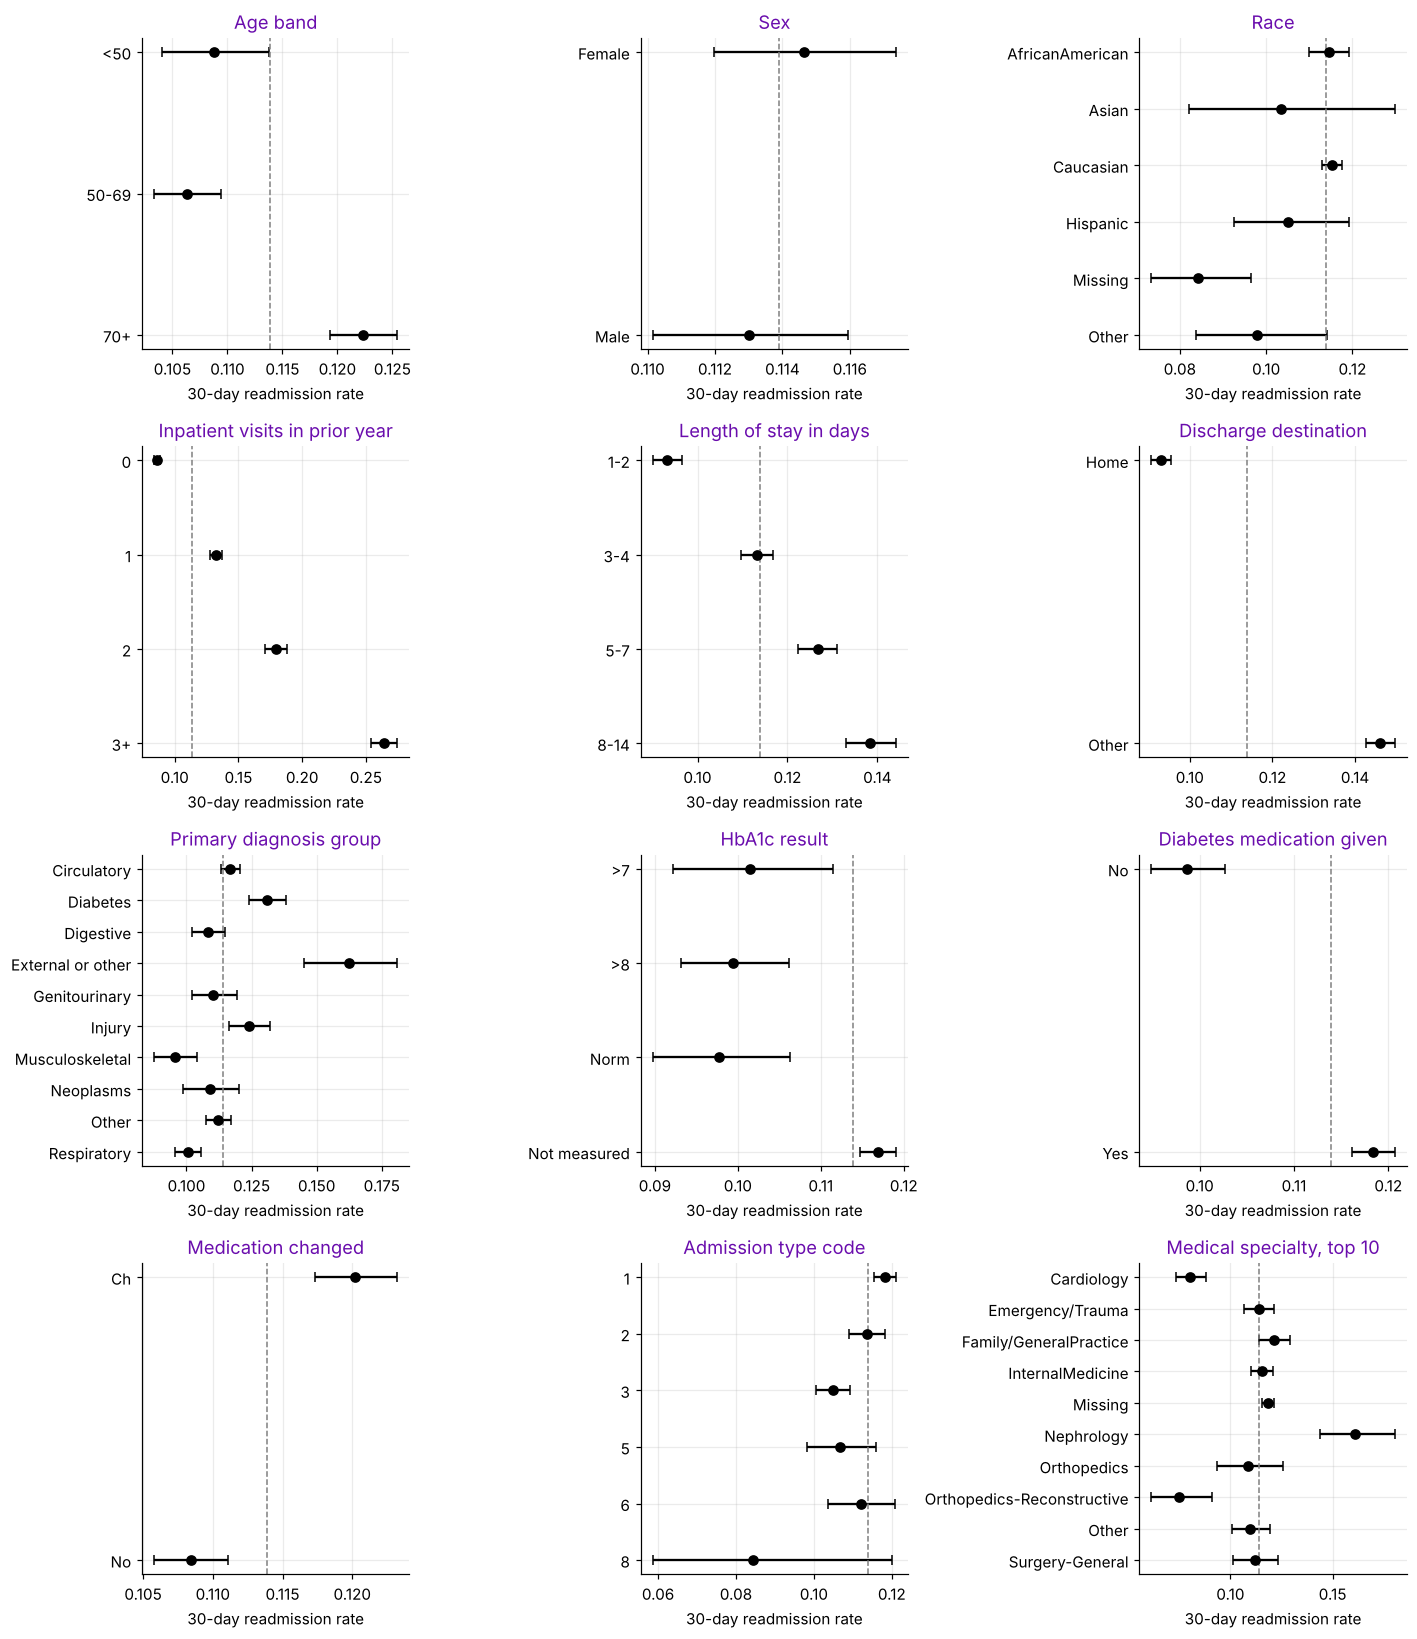

In [6]:
def wilson(k, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    p = k / n
    d = 1 + z ** 2 / n
    c = (p + z ** 2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / d
    return c - h, c + h


def rate_table(data, col, order=None, min_n=200):
    g = data.groupby(col, observed=True)["y"].agg(events="sum", n="count")
    g = g[g["n"] >= min_n].copy()
    ci = [wilson(k, n) for k, n in zip(g["events"], g["n"])]
    g["rate"] = g["events"] / g["n"]
    g["lo"] = [c[0] for c in ci]
    g["hi"] = [c[1] for c in ci]
    if order is not None:
        g = g.reindex([o for o in order if o in g.index])
    return g


overall = df["y"].mean()
lo, hi = wilson(df["y"].sum(), len(df))
print(f"Overall 30-day readmission rate: {overall:.2%} (95% CI {lo:.2%} to {hi:.2%}) across {len(df):,} encounters")

top_specialty = df["medical_specialty"].value_counts().head(10).index
panels = [
    ("age_band", ["<50", "50-69", "70+"], "Age band"),
    ("gender", None, "Sex"),
    ("race", None, "Race"),
    ("prior_inpatient_band", ["0", "1", "2", "3+"], "Inpatient visits in prior year"),
    ("los_band", ["1-2", "3-4", "5-7", "8-14"], "Length of stay in days"),
    ("discharge_group", None, "Discharge destination"),
    ("diag_1_grp", None, "Primary diagnosis group"),
    ("A1Cresult", None, "HbA1c result"),
    ("diabetesMed", None, "Diabetes medication given"),
    ("change", None, "Medication changed"),
    ("admission_type_id", None, "Admission type code"),
    ("medical_specialty", None, "Medical specialty, top 10"),
]
fig, axes = plt.subplots(4, 3, figsize=(13, 15))
eda_tables = {}
for ax, (col, order, title) in zip(axes.ravel(), panels):
    data = df[df["medical_specialty"].isin(top_specialty)] if col == "medical_specialty" else df
    t = rate_table(data, col, order)
    eda_tables[col] = t
    yy = np.arange(len(t))
    ax.errorbar(t["rate"], yy, xerr=[t["rate"] - t["lo"], t["hi"] - t["rate"]], fmt="o", color="black", capsize=3)
    ax.axvline(overall, ls="--", lw=1, color="grey")
    ax.set_yticks(yy)
    ax.set_yticklabels(t.index.astype(str))
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel("30-day readmission rate")
savefig("03_rates_by_group")
savetable(pd.concat(eda_tables, names=["variable", "level"]), "eda_rates_by_group")

**What this shows (RQ1).** Each point is a readmission rate with a 95 percent interval and the dashed line is the overall rate of 11.4 percent.

- Prior inpatient visits show the clearest gradient. The rate rises from 8.6 percent with none to 13.3, 17.9 and 26.4 percent with one, two and three or more visits.
- Patients discharged home were readmitted less often (9.3 percent) than patients sent elsewhere (14.6 percent).
- Longer stays carry higher rates, from 9.3 percent for 1 to 2 days to 13.8 percent for 8 to 14 days.
- Age 70 and over has 12.2 percent against 10.6 to 10.9 percent in the younger bands.
- A primary diagnosis of diabetes (13.1 percent) and the nephrology specialty (16.1 percent) are higher while cardiology (8.0 percent) is lower.
- When HbA1c was not measured the rate was 11.7 percent against about 10 percent when it was.
- Sex and race differ very little, all near 11.3 to 11.5 percent. Small race groups have wide intervals.

**Why it matters for the research.** Prior hospital use and discharge destination separate risk groups far more than demographic characteristics do. This anticipates which features the models will rely on.

<h3 style="color:#6A0DAD;">6.2 Numeric features by outcome</h3>

Histograms are drawn on the same bins for patients who were and were not readmitted within 30 days. The upper 1 percent of each feature is clipped for display.

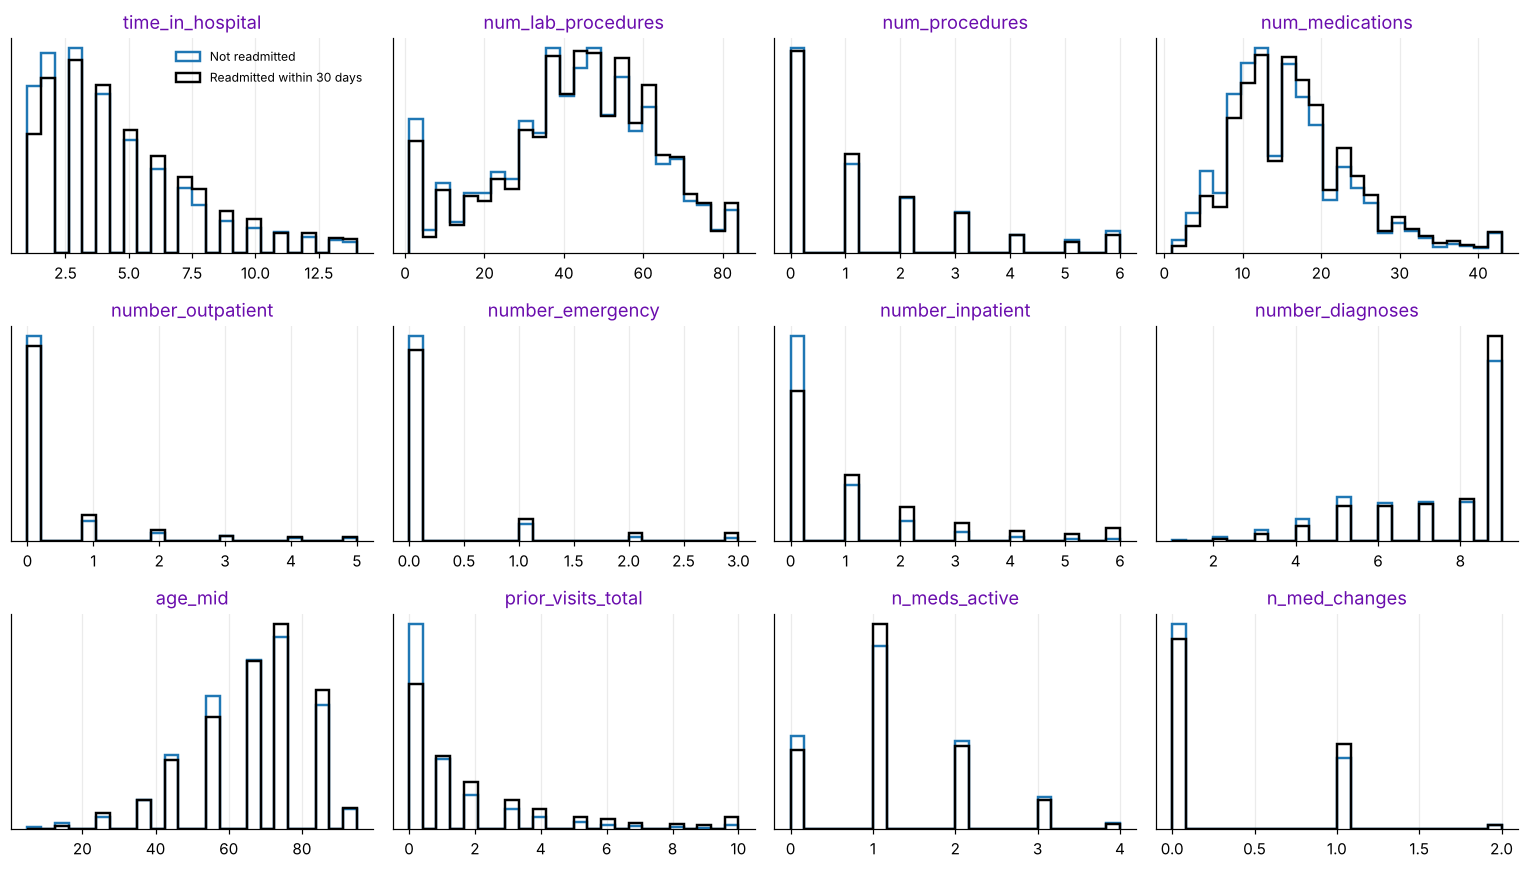

y                       0             1       
                     mean median   mean median
time_in_hospital     4.33    4.0   4.77    4.0
num_lab_procedures  42.74   44.0  44.22   45.0
num_procedures       1.34    1.0   1.28    1.0
num_medications     15.86   15.0  16.91   16.0
number_outpatient    0.36    0.0   0.44    0.0
number_emergency     0.18    0.0   0.36    0.0
number_inpatient     0.55    0.0   1.22    0.0
number_diagnoses     7.36    8.0   7.69    9.0
age_mid             65.62   65.0  66.73   65.0
prior_visits_total   1.09    0.0   2.02    1.0
n_meds_active        1.19    1.0   1.19    1.0
n_med_changes        0.28    0.0   0.34    0.0

In [7]:
fig, axes = plt.subplots(3, 4, figsize=(14, 8))
for ax, col in zip(axes.ravel(), NUM_MODEL):
    upper = df[col].quantile(0.99)
    bins = np.linspace(df[col].min(), max(upper, df[col].min() + 1), 25)
    for label, name, style in [(0, "Not readmitted", "step"), (1, "Readmitted within 30 days", "step")]:
        ax.hist(df.loc[df["y"] == label, col].clip(upper=upper), bins=bins, density=True, histtype=style,
                lw=1.6, label=name, color="black" if label else "tab:blue")
    ax.set_title(col)
    ax.set_yticks([])
axes.ravel()[0].legend(frameon=False, fontsize=8)
savefig("04_numeric_distributions")

summary = df.groupby("y")[NUM_MODEL].agg(["mean", "median"]).T.unstack()
display(summary.round(2))

**What this shows.** The histograms compare patients who were and were not readmitted on the same bins. The means differ in the expected direction, for example 1.22 against 0.55 prior inpatient visits, 0.36 against 0.18 emergency visits, 16.9 against 15.9 medications and 4.8 against 4.3 days in hospital. The distributions overlap heavily and many medians are identical, for example zero prior inpatient visits in both groups.

**Why it matters for the research.** No single variable separates the two groups cleanly. This foreshadows a modest ceiling for any prediction model built from these features.

<h3 style="color:#6A0DAD;">6.3 Correlation structure</h3>

Spearman correlations among the numeric features and the outcome. High correlation between predictors warns of multicollinearity and the outcome row shows the strongest univariate signals.

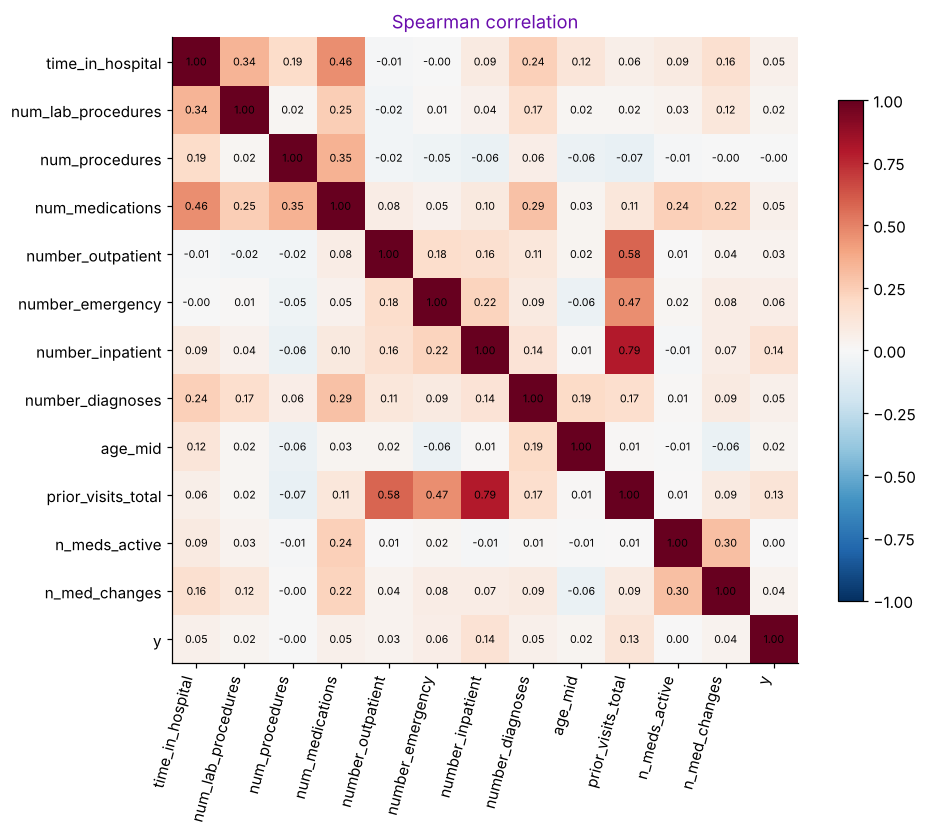

,spearman_with_outcome
number_inpatient,0.141
prior_visits_total,0.126
number_emergency,0.064
time_in_hospital,0.053
number_diagnoses,0.052
num_medications,0.048
n_med_changes,0.038
number_outpatient,0.035
age_mid,0.024
num_lab_procedures,0.024


In [8]:
cols = NUM_MODEL + ["y"]
corr = df[cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)))
ax.set_yticks(range(len(cols)))
ax.set_xticklabels(cols, rotation=75, ha="right")
ax.set_yticklabels(cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Spearman correlation")
savefig("05_correlation_heatmap")
display(corr["y"].drop("y").sort_values(ascending=False).round(3).to_frame("spearman_with_outcome"))

**What this shows.** The heatmap gives Spearman correlations between numeric features and with the outcome. The outcome row is the useful part. The strongest links are number_inpatient (0.141) and prior_visits_total (0.126), then number_emergency (0.064), time_in_hospital (0.053) and number_diagnoses (0.052). Every correlation is below 0.15 so each single association is weak, and num_procedures is essentially unrelated (minus 0.005). The engineered prior_visits_total correlates with its three components by construction.

**Why it matters for the research.** Many weak signals must be combined to predict readmission, which is what the models do. It also explains why a ceiling near an AUROC of 0.67 is plausible.

<h3 style="color:#6A0DAD;">6.4 Patient structure and why it matters</h3>

A readmission within 30 days is itself a second encounter so patients who were readmitted must have at least two encounters. This part of the pattern is mechanical and does not show that frequent patients are sicker. The pattern still matters for modelling because if the same patient is in both training and test data a model can score well by recognising the patient and not by learning generalisable patterns. The table uses the total number of encounters per patient. This is for exploration only because it is not known at prediction time.

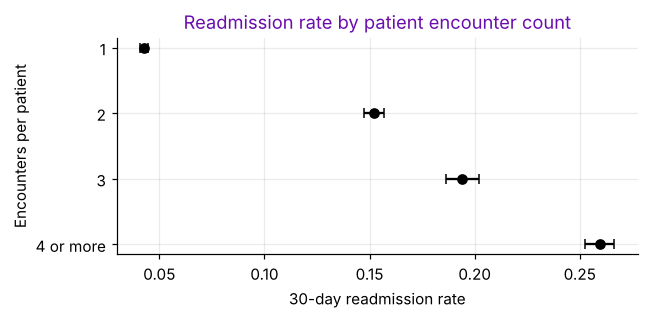

,events,n,rate,lo,hi
enc_band,,,,,
1,2287,53646,0.0426,0.0410,0.0444
2,3108,20436,0.1521,0.1472,0.1571
3,1882,9699,0.1940,0.1863,0.2020
4 or more,4037,15559,0.2595,0.2526,0.2664


In [9]:
enc_count = df.groupby("patient_nbr")["encounter_id"].transform("count")
tmp = df.assign(enc_band=pd.cut(enc_count, [0, 1, 2, 3, 1000], labels=["1", "2", "3", "4 or more"]).astype(str))
t = rate_table(tmp, "enc_band", ["1", "2", "3", "4 or more"], min_n=50)
fig, ax = plt.subplots(figsize=(6, 3))
yy = np.arange(len(t))
ax.errorbar(t["rate"], yy, xerr=[t["rate"] - t["lo"], t["hi"] - t["rate"]], fmt="o", color="black", capsize=3)
ax.set_yticks(yy)
ax.set_yticklabels(t.index)
ax.invert_yaxis()
ax.set_xlabel("30-day readmission rate")
ax.set_ylabel("Encounters per patient")
ax.set_title("Readmission rate by patient encounter count")
savefig("06_rate_by_patient_encounters")
display(t.round(4))

**What this shows.** The readmission rate rises from 4.3 percent for patients seen once to 15.2, 19.4 and 26.0 percent for two, three and four or more encounters. Treat this with care because a readmission is itself a second encounter, so the pattern is largely mechanical and does not show that frequent patients are sicker. It does show that patients with two or more encounters supply about 80 percent of all readmission events (9,027 of 11,314).

**Why it matters for the research.** Repeat patients dominate the outcome. This is the reason the split is made by patient and the reason clustered standard errors and clustered bootstrap intervals are used.

<h2 style="color:#6A0DAD;">7. Statistical inference (RQ2)</h2>

<h3 style="color:#6A0DAD;">7.1 Sample for the tests</h3>

Standard tests assume independent observations. Repeat encounters of one patient are not independent so the univariate tests use one row per patient, the first encounter after sorting by encounter id. The file has no timestamps so the ordering is a convention and it only decides which encounter represents each patient. The regression in section 7.4 uses all encounters and accounts for repeat patients with clustered standard errors.

In [10]:
index_df = df.sort_values("encounter_id").drop_duplicates("patient_nbr").reset_index(drop=True)
print(f"Index encounters: {len(index_df):,}   readmission rate {index_df['y'].mean():.2%}")

Index encounters: 69,987   readmission rate 8.98%


<h3 style="color:#6A0DAD;">7.2 Categorical factors</h3>

Chi-square test of independence between each factor and readmission, with Cramer's V as the effect size (Cramer, 1946). Levels with fewer than 30 patients are dropped from a test. P-values are adjusted for the family of tests with the Benjamini-Hochberg false discovery rate. The column min_expected shows the smallest expected cell count and values below 5 would call for caution.

,levels,n,chi2,dof,p,cramers_v,min_expected,p_adj_BH,significant_5pct
variable,,,,,,,,,
discharge_disposition_id,14,69931,1320.9080,13,0.0000,0.1374,3.5927,0.0000,True
any_prior_inpatient,2,69987,467.9491,1,0.0000,0.0818,735.9306,0.0000,True
age_band,3,69987,145.2479,2,0.0000,0.0456,1017.2815,0.0000,True
diag_1_grp,10,69977,98.5366,9,0.0000,0.0375,82.5139,0.0000,True
medical_specialty,16,69987,86.7804,15,0.0000,0.0352,43.8236,0.0000,True
diag_3_grp,11,69987,64.9731,10,0.0000,0.0305,102.9135,0.0000,True
diabetesMed,2,69987,53.7831,1,0.0000,0.0277,1498.3529,0.0000,True
diag_2_grp,11,69987,51.4437,10,0.0000,0.0271,26.3121,0.0000,True
insulin,4,69987,49.6730,3,0.0000,0.0266,608.5908,0.0000,True


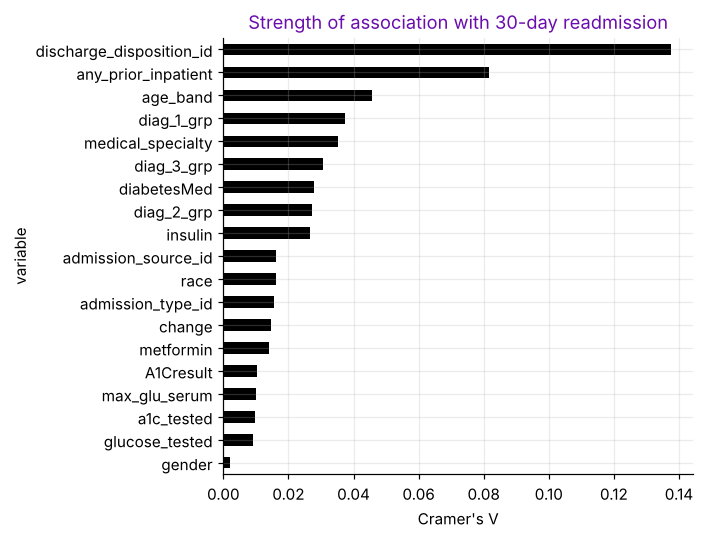

In [11]:
CAT_TESTS = ["age_band", "gender", "race", "admission_type_id", "admission_source_id", "discharge_disposition_id",
             "medical_specialty", "diag_1_grp", "diag_2_grp", "diag_3_grp", "max_glu_serum", "A1Cresult",
             "a1c_tested", "glucose_tested", "change", "diabetesMed", "insulin", "metformin", "any_prior_inpatient"]


def chi2_test(data, col):
    ct = pd.crosstab(data[col], data["y"])
    ct = ct[ct.sum(axis=1) >= 30]
    chi2, p, dof, expected = stats.chi2_contingency(ct, correction=False)
    n = ct.values.sum()
    k = min(ct.shape) - 1
    return {"variable": col, "levels": ct.shape[0], "n": int(n), "chi2": chi2, "dof": dof, "p": p,
            "cramers_v": np.sqrt(chi2 / (n * k)) if k > 0 else np.nan, "min_expected": expected.min()}


chi_table = pd.DataFrame([chi2_test(index_df, c) for c in CAT_TESTS])
chi_table["p_adj_BH"] = multipletests(chi_table["p"], method="fdr_bh")[1]
chi_table["significant_5pct"] = chi_table["p_adj_BH"] < 0.05
chi_table = chi_table.sort_values("cramers_v", ascending=False).set_index("variable")
display(chi_table.round(4))
savetable(chi_table, "stats_chi_square")

fig, ax = plt.subplots(figsize=(6.5, 5))
chi_table["cramers_v"].sort_values().plot.barh(ax=ax, color="black")
ax.set_xlabel("Cramer's V")
ax.set_title("Strength of association with 30-day readmission")
savefig("07_cramers_v")

**What this shows (RQ2).** Chi-square tests on one row per patient (69,987 patients, index readmission rate 8.98 percent, which is lower than the 11.4 percent in the full data because patients with many encounters contribute many rows there). After Benjamini-Hochberg adjustment 16 of 19 factors are significant. The effects are small. Cramer's V is highest for discharge disposition (0.137), then any prior inpatient visit (0.082), age band (0.046), primary diagnosis (0.038) and medical specialty (0.035). Sex shows no association (V 0.002, p 0.58). HbA1c result category and glucose result category are not significant after adjustment (adjusted p 0.069 and 0.080). Discharge disposition has a sparse cell with a minimum expected count of 3.6, so its test is less reliable than the others.

**Why it matters for the research.** With this many patients significance is cheap. The effect sizes show that every categorical association is weak, so the p-values alone would overstate their importance.

<h3 style="color:#6A0DAD;">7.3 Numeric factors</h3>

Mann-Whitney U test comparing patients who were and were not readmitted. The probability of superiority is U divided by the product of the group sizes. It is the chance that a randomly chosen readmitted patient has a larger value than a randomly chosen patient who was not readmitted with ties counted as half. A value of 0.5 means no difference and it equals the AUROC of the single feature (Mann and Whitney, 1947).

,median_readmitted,median_not_readmitted,U,p,prob_superiority,p_adj_BH,distance_from_0.5
variable,,,,,,,
time_in_hospital,4.0,3.0,224082491.5,0.0000,0.5597,0.0000,0.0597
prior_visits_total,0.0,0.0,220432834.0,0.0000,0.5506,0.0000,0.0506
age_mid,75.0,65.0,219376867.0,0.0000,0.5479,0.0000,0.0479
number_inpatient,0.0,0.0,219252820.0,0.0000,0.5476,0.0000,0.0476
num_medications,15.0,14.0,217343565.0,0.0000,0.5429,0.0000,0.0429
number_diagnoses,8.0,8.0,216840923.0,0.0000,0.5416,0.0000,0.0416
num_lab_procedures,46.0,44.0,213277394.0,0.0000,0.5327,0.0000,0.0327
n_med_changes,0.0,0.0,207134066.5,0.0000,0.5174,0.0000,0.0174
n_meds_active,1.0,1.0,205807505.0,0.0001,0.5140,0.0001,0.0140


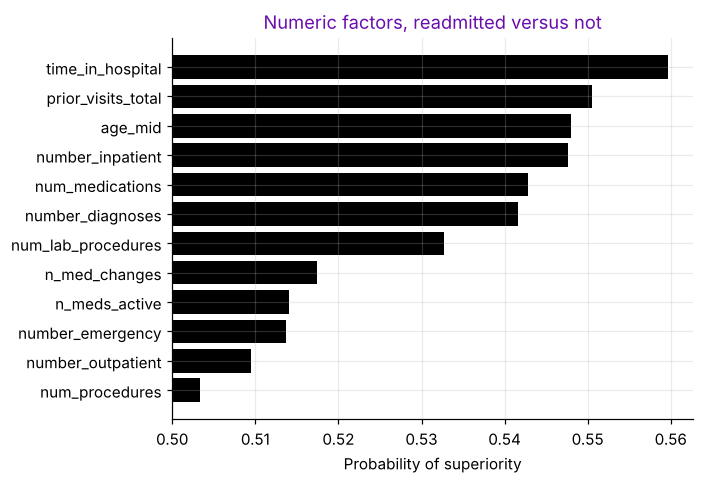

In [12]:
def mw_test(data, col):
    a = data.loc[data["y"] == 1, col].dropna()
    b = data.loc[data["y"] == 0, col].dropna()
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    return {"variable": col, "median_readmitted": a.median(), "median_not_readmitted": b.median(),
            "U": u, "p": p, "prob_superiority": u / (len(a) * len(b))}


mw_table = pd.DataFrame([mw_test(index_df, c) for c in NUM_MODEL])
mw_table["p_adj_BH"] = multipletests(mw_table["p"], method="fdr_bh")[1]
mw_table["distance_from_0.5"] = (mw_table["prob_superiority"] - 0.5).abs()
mw_table = mw_table.sort_values("distance_from_0.5", ascending=False).set_index("variable")
display(mw_table.round(4))
savetable(mw_table, "stats_mann_whitney")

fig, ax = plt.subplots(figsize=(6.5, 4.5))
vals = mw_table["prob_superiority"].sort_values()
ax.barh(vals.index, vals - 0.5, left=0.5, color="black")
ax.axvline(0.5, color="grey", lw=1)
ax.set_xlabel("Probability of superiority")
ax.set_title("Numeric factors, readmitted versus not")
savefig("08_probability_of_superiority")

**What this shows (RQ2).** Mann-Whitney tests compare readmitted and not readmitted patients. Eleven of 12 numeric features differ significantly. The probability of superiority is largest for time in hospital (0.560), then prior_visits_total (0.551), age (0.548), number_inpatient (0.548), number of medications (0.543) and number of diagnoses (0.542). A value of 0.5 would mean no difference so even the largest gap is modest. The number of procedures shows no difference (0.503, p 0.36).

**Why it matters for the research.** The ranking differs a little from the correlation ranking because a rank test also picks up spread and not only trend. The consistent message is that each numeric feature carries a small amount of information.

<h3 style="color:#6A0DAD;">7.4 Multivariable logistic regression</h3>

Odds ratios from one model with all encounters and standard errors clustered by patient. Continuous factors are expressed per unit shown in the name. Reference groups are circulatory primary diagnosis and Caucasian race. The variance inflation factor check follows the table.

,odds_ratio,ci_low,ci_high,p,p_adj_BH
dx_Missing,2.1081,0.7994,5.5594,0.1317,0.1981
number_inpatient,1.3030,1.2861,1.3200,0.0000,0.0000
on_diabetes_medication,1.1900,1.1229,1.2612,0.0000,0.0000
dx_External or other,1.1292,0.9697,1.3149,0.1178,0.1963
dx_Diabetes,1.0484,0.9654,1.1384,0.2615,0.3269
race_Asian,1.0448,0.7996,1.3653,0.7480,0.8032
number_diagnoses,1.0413,1.0283,1.0544,0.0000,0.0000
emergency_admission,1.0394,0.9941,1.0868,0.0888,0.1567
number_emergency,1.0389,1.0126,1.0659,0.0035,0.0104
male,1.0319,0.9898,1.0757,0.1398,0.1981


Pseudo R-squared 0.0416   in-sample AUROC 0.651


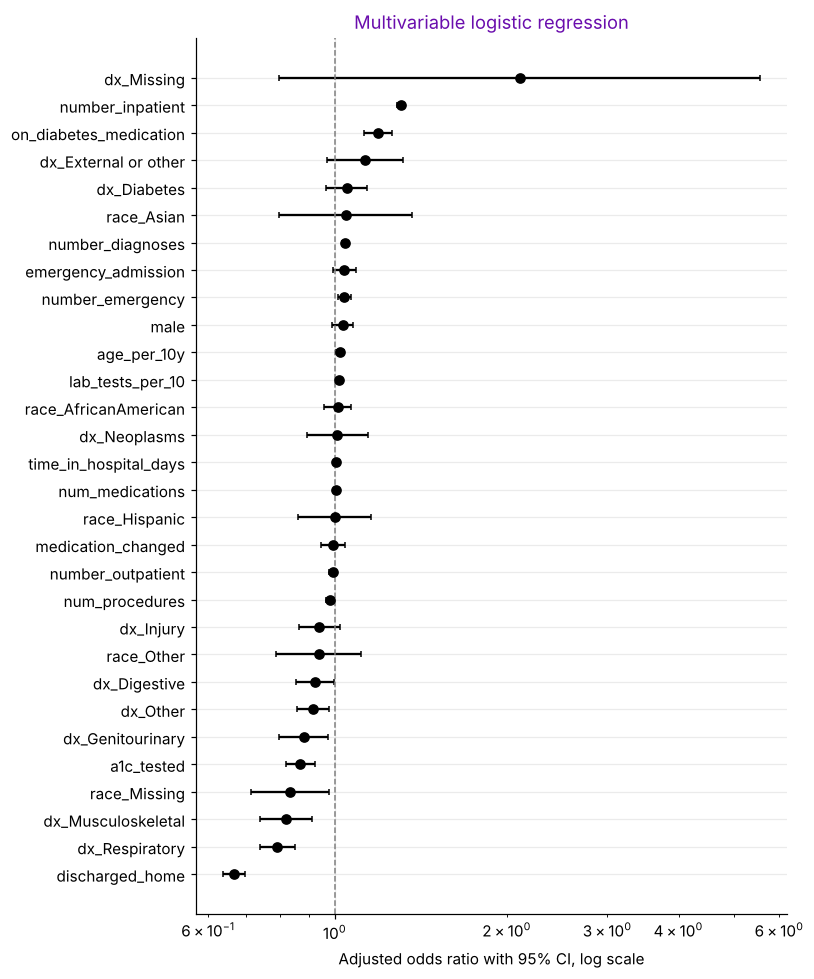

In [13]:
def design(data):
    X = pd.DataFrame({
        "age_per_10y": data["age10"],
        "number_inpatient": data["number_inpatient"],
        "number_emergency": data["number_emergency"],
        "number_outpatient": data["number_outpatient"],
        "time_in_hospital_days": data["time_in_hospital"],
        "number_diagnoses": data["number_diagnoses"],
        "num_medications": data["num_medications"],
        "num_procedures": data["num_procedures"],
        "lab_tests_per_10": data["lab10"],
        "a1c_tested": data["a1c_tested"],
        "on_diabetes_medication": (data["diabetesMed"] == "Yes").astype(int),
        "medication_changed": (data["change"] == "Ch").astype(int),
        "male": (data["gender"] == "Male").astype(int),
        "discharged_home": data["discharge_home"],
        "emergency_admission": (data["admission_type_id"] == "1").astype(int),
    }, index=data.index)
    dx = pd.get_dummies(data["diag_1_grp"], prefix="dx").drop(columns="dx_Circulatory", errors="ignore").astype(int)
    race = pd.get_dummies(data["race"], prefix="race").drop(columns="race_Caucasian", errors="ignore").astype(int)
    return pd.concat([X, dx, race], axis=1)


Xr = design(df)
groups_all = pd.factorize(df["patient_nbr"])[0]
logit_fit = sm.Logit(df["y"].values, sm.add_constant(Xr)).fit(disp=0, cov_type="cluster", cov_kwds={"groups": groups_all}, maxiter=200)
ci = logit_fit.conf_int()
or_table = pd.DataFrame({"odds_ratio": np.exp(logit_fit.params), "ci_low": np.exp(ci[0]), "ci_high": np.exp(ci[1]),
                         "p": logit_fit.pvalues}).drop(index="const")
or_table["p_adj_BH"] = multipletests(or_table["p"], method="fdr_bh")[1]
display(or_table.sort_values("odds_ratio", ascending=False).round(4))
savetable(or_table, "stats_logistic_odds_ratios")
print(f"Pseudo R-squared {logit_fit.prsquared:.4f}   in-sample AUROC {roc_auc_score(df['y'], logit_fit.predict(sm.add_constant(Xr))):.3f}")

t = or_table.sort_values("odds_ratio")
fig, ax = plt.subplots(figsize=(7.5, 9))
yy = np.arange(len(t))
ax.errorbar(t["odds_ratio"], yy, xerr=[t["odds_ratio"] - t["ci_low"], t["ci_high"] - t["odds_ratio"]], fmt="o", color="black", capsize=2)
ax.axvline(1, color="grey", ls="--", lw=1)
ax.set_xscale("log")
ax.set_yticks(yy)
ax.set_yticklabels(t.index)
ax.set_xlabel("Adjusted odds ratio with 95% CI, log scale")
ax.set_title("Multivariable logistic regression")
savefig("09_odds_ratio_forest")

**What this shows (RQ2).** The forest plot gives adjusted odds ratios with patient-clustered 95 percent intervals. Points to the right of the dashed line raise the odds of readmission and points to the left lower them.

- Each additional inpatient visit in the prior year multiplies the odds by 1.30 (1.29 to 1.32).
- Discharge to home lowers the odds (0.67, 0.64 to 0.70).
- Having a diabetes medication prescribed raises them (1.19, 1.12 to 1.26).
- Having HbA1c measured lowers them (0.87, 0.82 to 0.92).
- Compared with a circulatory primary diagnosis, respiratory (0.79) and musculoskeletal (0.82) diagnoses carry lower odds.
- Age adds 2 percent per decade (1.02). Sex, race, medication change and outpatient visits show no clear adjusted association.
- The category for a missing primary diagnosis has an odds ratio of 2.1 with a very wide interval (0.80 to 5.56) because it rests on very few patients and should not be interpreted.

The model explains little. Pseudo R-squared is 0.042 and the in-sample AUROC is 0.651.

**Why it matters for the research.** H1 is largely supported because prior inpatient visits show the strongest dose-response relationship, although discharge destination is a close competitor. These are associations and not causes. For example discharge home may mark healthier patients and need not protect them.

In [14]:
vif_cols = ["age_per_10y", "number_inpatient", "number_emergency", "number_outpatient", "time_in_hospital_days",
            "number_diagnoses", "num_medications", "num_procedures", "lab_tests_per_10"]
V = sm.add_constant(Xr[vif_cols])
vif = pd.Series([variance_inflation_factor(V.values, i) for i in range(1, V.shape[1])], index=vif_cols, name="VIF")
display(vif.round(2).to_frame())
print("Values below about 5 suggest no serious multicollinearity.")

,VIF
age_per_10y,1.09
number_inpatient,1.11
number_emergency,1.09
number_outpatient,1.03
time_in_hospital_days,1.38
number_diagnoses,1.18
num_medications,1.53
num_procedures,1.19
lab_tests_per_10,1.15


Values below about 5 suggest no serious multicollinearity.


**What this shows.** The largest variance inflation factor is 1.53 (number of medications) and the rest are close to 1. There is no multicollinearity problem so the odds ratios above are not distorted by overlapping predictors.

<h3 style="color:#6A0DAD;">7.5 HbA1c measurement and readmission</h3>

Strack et al. (2014) reported that the link between HbA1c measurement and readmission depends on the primary diagnosis. We test this in three steps on the independent index sample. First the unadjusted association. Second the odds ratio within each diagnosis group. Third a likelihood ratio test for an interaction between HbA1c measurement and diagnosis group in a model adjusted for the other factors. A significant interaction means the association differs by diagnosis group.

Readmission rate HbA1c measured 8.40%, not measured 9.11%, chi-square p 0.01084


,n,odds_ratio_tested_vs_not,ci_low,ci_high
diagnosis_group,,,,
Circulatory,21389,1.076,0.961,1.205
Diabetes,5748,0.690,0.566,0.840
Digestive,6488,0.924,0.703,1.214
External or other,919,0.480,0.180,1.276
Genitourinary,3441,1.172,0.861,1.595
Injury,4694,0.623,0.449,0.864
Musculoskeletal,4064,1.132,0.793,1.615
Neoplasms,2538,1.164,0.754,1.796
Other,11205,0.979,0.827,1.157


Interaction likelihood ratio test chi-square 24.60 on 9 df, p 0.003447
Adjusted odds ratio for HbA1c measured in the main-effects model 0.944


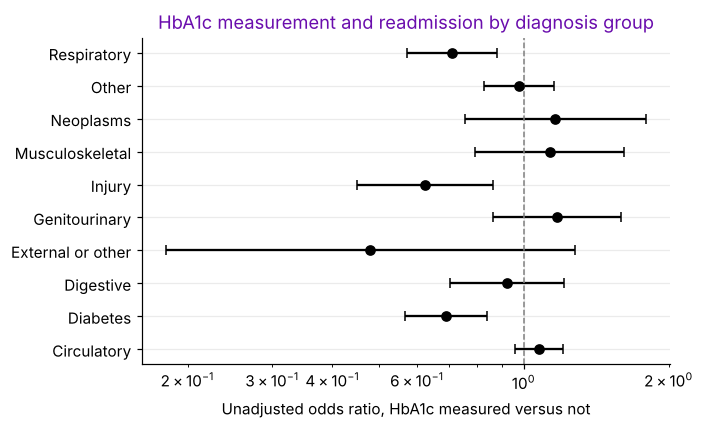

In [15]:
ct = pd.crosstab(index_df["a1c_tested"], index_df["y"])
chi2, p, _, _ = stats.chi2_contingency(ct, correction=False)
rate_tested = index_df.loc[index_df["a1c_tested"] == 1, "y"].mean()
rate_not = index_df.loc[index_df["a1c_tested"] == 0, "y"].mean()
print(f"Readmission rate HbA1c measured {rate_tested:.2%}, not measured {rate_not:.2%}, chi-square p {p:.4g}")

rows = []
for grp, sub in index_df.groupby("diag_1_grp"):
    if len(sub) < 300:
        continue
    table = pd.crosstab(sub["a1c_tested"], sub["y"]).reindex(index=[1, 0], columns=[1, 0], fill_value=0) + 0.5
    t2 = Table2x2(table.values)
    lo_, hi_ = t2.oddsratio_confint()
    rows.append({"diagnosis_group": grp, "n": len(sub), "odds_ratio_tested_vs_not": t2.oddsratio, "ci_low": lo_, "ci_high": hi_})
strat = pd.DataFrame(rows).set_index("diagnosis_group")
display(strat.round(3))
savetable(strat, "stats_a1c_by_diagnosis")

big = index_df[index_df["diag_1_grp"].map(index_df["diag_1_grp"].value_counts()) >= 300]
adj = "y ~ a1c_tested + C(diag_1_grp) + age10 + number_inpatient + number_emergency + number_outpatient + time_in_hospital + number_diagnoses + num_medications"
try:
    m0 = smf.logit(adj, data=big).fit(disp=0)
    m1 = smf.logit(adj + " + a1c_tested:C(diag_1_grp)", data=big).fit(disp=0)
    lr_stat = 2 * (m1.llf - m0.llf)
    lr_df = int(m1.df_model - m0.df_model)
    lr_p = stats.chi2.sf(lr_stat, lr_df)
    print(f"Interaction likelihood ratio test chi-square {lr_stat:.2f} on {lr_df} df, p {lr_p:.4g}")
    print(f"Adjusted odds ratio for HbA1c measured in the main-effects model {np.exp(m0.params['a1c_tested']):.3f}")
except Exception as exc:
    print("Interaction model could not be fitted:", exc)

fig, ax = plt.subplots(figsize=(6.5, 4))
yy = np.arange(len(strat))
ax.errorbar(strat["odds_ratio_tested_vs_not"], yy, xerr=[strat["odds_ratio_tested_vs_not"] - strat["ci_low"], strat["ci_high"] - strat["odds_ratio_tested_vs_not"]], fmt="o", color="black", capsize=3)
ax.axvline(1, ls="--", color="grey", lw=1)
ax.set_xscale("log")
ax.set_yticks(yy)
ax.set_yticklabels(strat.index)
ax.set_xlabel("Unadjusted odds ratio, HbA1c measured versus not")
ax.set_title("HbA1c measurement and readmission by diagnosis group")
savefig("10_a1c_by_diagnosis")

**What this shows (RQ2, H2).** Among index encounters the readmission rate was 8.40 percent when HbA1c was measured and 9.11 percent when it was not (p 0.011). The forest plot shows the unadjusted odds ratio within each primary diagnosis group. Measurement is associated with lower odds for diabetes (0.69, 0.57 to 0.84), respiratory (0.71, 0.57 to 0.88) and injury (0.62, 0.45 to 0.86) diagnoses. For circulatory, digestive, genitourinary, musculoskeletal, neoplasm and other diagnoses the intervals include 1. The likelihood ratio test for interaction is significant (chi-square 24.60 on 9 degrees of freedom, p 0.0034). The adjusted odds ratio in the main-effects model is 0.944.

**Why it matters for the research.** H2 is supported. The association between HbA1c measurement and readmission is not the same in every diagnosis group, which agrees with what Strack et al. (2014) reported. The overall effect after adjustment is small, so measurement alone is not a strong lever.

<h2 style="color:#6A0DAD;">8. Patient-level data split</h2>

The data are split into train 60 percent, validation 10 percent, calibration 10 percent and test 20 percent. Whole patients are assigned to one set only. The dataset documentation recommends a three-way holdout when selecting models (Clore et al., 2014). The validation set tunes hyperparameters and early stopping. The calibration set is used only to fit recalibration maps. The test set is touched only for final evaluation. This design addresses the leakage risks described by Kapoor and Narayanan (2023).

In [16]:
def assign_split(keys, seed=SEED):
    codes, uniq = pd.factorize(pd.Series(keys))
    perm = np.random.default_rng(seed).permutation(len(uniq))
    rank = np.empty(len(uniq), dtype=int)
    rank[perm] = np.arange(len(uniq))
    frac = rank / len(uniq)
    labels = np.select([frac < 0.6, frac < 0.7, frac < 0.8], ["train", "val", "calib"], "test")
    return labels[codes]


SPLITS = ["train", "val", "calib", "test"]
split = assign_split(df["patient_nbr"].values)
m = {s: split == s for s in SPLITS}
y = df["y"].values
pid = df["patient_nbr"].values

for a in SPLITS:
    for b in SPLITS:
        if a < b:
            assert not set(pid[m[a]]) & set(pid[m[b]]), "patient overlap between splits"
print("Check passed, no patient appears in more than one split")

split_table = pd.DataFrame({
    "encounters": {s: int(m[s].sum()) for s in SPLITS},
    "patients": {s: int(len(np.unique(pid[m[s]]))) for s in SPLITS},
    "readmission_rate": {s: round(float(y[m[s]].mean()), 4) for s in SPLITS},
})
display(split_table)
savetable(split_table, "split_summary")
pd.DataFrame({"encounter_id": df["encounter_id"], "patient_nbr": df["patient_nbr"], "split": split}).to_csv(DATA_DIR / "split_assignment.csv", index=False)

Check passed, no patient appears in more than one split


,encounters,patients,readmission_rate
train,59517,41993,0.1134
val,9824,6998,0.1083
calib,10027,6999,0.1139
test,19972,13997,0.1182


**What this shows.** The training set has 59,517 encounters from 41,993 patients, validation 9,824 from 6,998, calibration 10,027 from 6,999 and test 19,972 from 13,997. The check confirms that no patient appears in more than one set. The readmission rate is 11.34 percent in training and 11.82 percent in the test set, with 10.83 and 11.39 percent in validation and calibration.

**Why it matters for the research.** The sets are well balanced, but the test prevalence is slightly higher than the training prevalence purely by chance. This small shift explains a pattern seen later in the calibration results. The assignment is saved in data/split_assignment.csv.

<h2 style="color:#6A0DAD;">9. Preprocessing</h2>

Numeric features are median-imputed and standardised. Categorical features are one-hot encoded and levels with fewer than 30 training rows are grouped together. The transformers are fitted on the training set only and then applied to the other sets. LightGBM uses the categorical columns directly.

In [17]:
def make_prep(num, cat):
    steps = [("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num)]
    if cat:
        steps.append(("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30, sparse_output=False), cat))
    return ColumnTransformer(steps)


X = df[FEATURES]
prep_full = make_prep(NUM_MODEL + FLAG_MODEL, CAT_MODEL).fit(X[m["train"]])
prep_simple = make_prep(SIMPLE, []).fit(X[m["train"]])
Z = {s: prep_full.transform(X[m[s]]) for s in SPLITS}
Zs = {s: prep_simple.transform(X[m[s]]) for s in SPLITS}

Xl = X.copy()
for c in CAT_MODEL:
    Xl[c] = pd.Categorical(Xl[c])
XL = {s: Xl[m[s]] for s in SPLITS}
Y = {s: y[m[s]] for s in SPLITS}
print("Design matrix width for scikit-learn models:", Z["train"].shape[1])

Design matrix width for scikit-learn models: 180


<h2 style="color:#6A0DAD;">10. Model training and tuning (RQ4)</h2>

Nine models are trained on the training set. Hyperparameters are chosen by validation AUROC only. Models that stop early use the patient-level validation set so that stopping is not influenced by the same patients appearing in training. The built-in early stopping of scikit-learn splits rows at random so it is switched off in favour of validation-based selection.

| Model | Purpose | Tuned |
|---|---|---|
| Prevalence only | Reference with no information | None |
| Logistic with 5 predictors | Simple clinical-style baseline | None |
| Logistic L2 | Regularised linear model | Regularisation strength |
| Logistic L1 | Sparse linear model (Tibshirani, 1996) | Regularisation strength |
| Decision tree | Interpretable nonlinear model | Depth |
| Random forest | Bagged trees (Breiman, 2001) | Leaf size |
| HistGradientBoosting | Boosted trees in scikit-learn (Pedregosa et al., 2011) | Leaves and number of trees |
| Neural network | Multilayer perceptron | Weight penalty and epochs |
| LightGBM | Boosted trees (Ke et al., 2017) | Leaves, early stopping |

In [18]:
RESULTS = {}      # model name -> dict with fitted model, validation AUROC, seconds
PRED = {}         # model name -> dict of split -> predicted probability


def auc_val(p):
    return roc_auc_score(Y["val"], p)


def register(name, model, predict, val_auc, seconds, params):
    RESULTS[name] = {"model": model, "val_auc": val_auc, "seconds": seconds, "params": params}
    PRED[name] = {s: predict(model, s) for s in ["val", "calib", "test"]}
    print(f"{name:28s} validation AUROC {val_auc:.4f}   params {params}   {seconds:.0f}s")


def tune_generic(name, builder, grid, data):
    best = None
    t0 = time.time()
    for params in grid:
        model = builder(**params).fit(data["train"], Y["train"])
        auc = auc_val(model.predict_proba(data["val"])[:, 1])
        if best is None or auc > best[0]:
            best = (auc, model, params)
    register(name, best[1], lambda mdl, s: mdl.predict_proba(data[s])[:, 1], best[0], time.time() - t0, best[2])


# Reference and linear models
tune_generic("Prevalence only", lambda: DummyClassifier(strategy="prior"), [{}], Z)
tune_generic("Logistic (5 predictors)", lambda: LogisticRegression(max_iter=2000), [{}], Zs)
tune_generic("Logistic L2", lambda C: LogisticRegression(C=C, max_iter=3000), [{"C": c} for c in [0.003, 0.01, 0.03, 0.1, 0.3, 1.0]], Z)
tune_generic("Logistic L1", lambda C: LogisticRegression(penalty="l1", solver="liblinear", C=C, max_iter=500),
             [{"C": c} for c in [0.01, 0.03, 0.1, 0.3]], Z)

# Trees and forests
tune_generic("Decision tree", lambda max_depth: DecisionTreeClassifier(max_depth=max_depth, min_samples_leaf=100, random_state=SEED),
             [{"max_depth": d} for d in [3, 5, 8]], Z)
tune_generic("Random forest", lambda min_samples_leaf: RandomForestClassifier(
    n_estimators=100 if FAST else 300, min_samples_leaf=min_samples_leaf, max_features="sqrt", n_jobs=-1, random_state=SEED),
    [{"min_samples_leaf": l} for l in [20, 50]], Z)

Prevalence only              validation AUROC 0.5000   params {}   0s
Logistic (5 predictors)      validation AUROC 0.6231   params {}   0s


Logistic L2                  validation AUROC 0.6585   params {'C': 0.03}   10s


Logistic L1                  validation AUROC 0.6594   params {'C': 0.1}   27s


Decision tree                validation AUROC 0.6411   params {'max_depth': 8}   1s


Random forest                validation AUROC 0.6586   params {'min_samples_leaf': 20}   41s


In [19]:
# HistGradientBoosting, number of trees chosen on the validation set
t0 = time.time()
best = None
for leaves in [15, 31]:
    big_model = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=200 if FAST else 600, max_leaf_nodes=leaves,
                                               min_samples_leaf=50, l2_regularization=1.0, early_stopping=False, random_state=SEED)
    big_model.fit(Z["train"], Y["train"])
    aucs = [roc_auc_score(Y["val"], p[:, 1]) for p in big_model.staged_predict_proba(Z["val"])]
    n_trees = int(np.argmax(aucs)) + 1
    if best is None or max(aucs) > best[0]:
        best = (max(aucs), leaves, n_trees)
final = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=best[2], max_leaf_nodes=best[1], min_samples_leaf=50,
                                       l2_regularization=1.0, early_stopping=False, random_state=SEED).fit(Z["train"], Y["train"])
register("HistGradientBoosting", final, lambda mdl, s: mdl.predict_proba(Z[s])[:, 1], best[0], time.time() - t0,
         {"leaves": best[1], "trees": best[2]})

# Neural network, number of epochs chosen on the validation set
t0 = time.time()
best = None
for alpha in [1e-3, 1e-2]:
    net = MLPClassifier(hidden_layer_sizes=(64, 32), alpha=alpha, random_state=SEED)
    local_best, local_epoch, snap = -1, 0, None
    for epoch in range(30):
        net.partial_fit(Z["train"], Y["train"], classes=np.array([0, 1]))
        auc = auc_val(net.predict_proba(Z["val"])[:, 1])
        if auc > local_best:
            local_best, local_epoch, snap = auc, epoch + 1, copy.deepcopy(net)
        elif epoch + 1 - local_epoch >= 4:
            break
    if best is None or local_best > best[0]:
        best = (local_best, snap, {"alpha": alpha, "epochs": local_epoch})
register("Neural network (MLP)", best[1], lambda mdl, s: mdl.predict_proba(Z[s])[:, 1], best[0], time.time() - t0, best[2])

# LightGBM with early stopping on the patient-level validation set
t0 = time.time()
best = None
for leaves in [15, 31, 63]:
    gbm = lgb.LGBMClassifier(n_estimators=3000, learning_rate=0.03, num_leaves=leaves, min_child_samples=50, subsample=0.8,
                             subsample_freq=1, colsample_bytree=0.8, reg_lambda=5.0, random_state=SEED, verbose=-1)
    gbm.fit(XL["train"], Y["train"], eval_set=[(XL["val"], Y["val"])], eval_metric="auc",
            callbacks=[lgb.early_stopping(100, verbose=False)])
    auc = auc_val(gbm.predict_proba(XL["val"])[:, 1])
    if best is None or auc > best[0]:
        best = (auc, gbm, {"leaves": leaves, "trees": int(gbm.best_iteration_ or gbm.n_estimators)})
register("LightGBM", best[1], lambda mdl, s: mdl.predict_proba(XL[s])[:, 1], best[0], time.time() - t0, best[2])

MODEL_NAMES = list(RESULTS)
tuning = pd.DataFrame({n: {"validation_AUROC": RESULTS[n]["val_auc"], "seconds": RESULTS[n]["seconds"],
                           "chosen_parameters": str(RESULTS[n]["params"])} for n in MODEL_NAMES}).T
display(tuning)
savetable(tuning, "model_tuning")

HistGradientBoosting         validation AUROC 0.6654   params {'leaves': 15, 'trees': 502}   100s


Neural network (MLP)         validation AUROC 0.6561   params {'alpha': 0.01, 'epochs': 4}   5s


LightGBM                     validation AUROC 0.6703   params {'leaves': 31, 'trees': 184}   11s


,validation_AUROC,seconds,chosen_parameters
Prevalence only,0.5,0.007315,{}
Logistic (5 predictors),0.623108,0.036147,{}
Logistic L2,0.658475,10.4326,{'C': 0.03}
Logistic L1,0.659427,27.38393,{'C': 0.1}
Decision tree,0.641071,1.32483,{'max_depth': 8}
Random forest,0.658561,41.153376,{'min_samples_leaf': 20}
HistGradientBoosting,0.665374,99.83442,"{'leaves': 15, 'trees': 502}"
Neural network (MLP),0.656101,4.871381,"{'alpha': 0.01, 'epochs': 4}"
LightGBM,0.670275,10.649343,"{'leaves': 31, 'trees': 184}"


**What this shows.** Validation AUROC ranks LightGBM first (0.670), then HistGradientBoosting (0.665), L1 logistic (0.660), random forest (0.659), L2 logistic (0.658), the neural network (0.656), the decision tree (0.641) and the five-predictor logistic model (0.623). The chosen settings are listed in the last column. All of this uses the validation set only.

**Why it matters for the research.** The test set was not used to choose anything, so the test results that follow are an honest estimate for new patients from the same hospitals.

<h2 style="color:#6A0DAD;">11. Model evaluation on held-out patients (RQ4, RQ5)</h2>

All numbers in this section come from the test set. Uncertainty comes from a patient-clustered bootstrap in which whole patients are resampled so that repeat encounters do not make the intervals too narrow (Field and Welsh, 2007). The same resamples are used for every model so differences between models are paired (Efron and Tibshirani, 1993).

Metrics. AUROC measures ranking ability. AUPRC measures precision and recall and its reference value is the prevalence. The Brier score is the mean squared error of the predicted probabilities (Brier, 1950). Calibration slope should be near 1 and values below 1 mean the predictions are too extreme. Calibration-in-the-large should be near 0 and positive values mean risks are underestimated. ECE is the average gap between predicted and observed risk across ten bins. Calibration is reported alongside discrimination because it is assessed far less often than it should be (Van Calster et al., 2019).

In [20]:
yt = Y["test"]
pid_test = pid[m["test"]]
codes_test = pd.factorize(pid_test)[0]
patient_rows = list(pd.Series(np.arange(len(yt))).groupby(codes_test).indices.values())


def boot_draws(B, seed=SEED):
    rng = np.random.default_rng(seed)
    out = []
    for _ in range(B):
        pick = rng.integers(0, len(patient_rows), len(patient_rows))
        out.append(np.concatenate([patient_rows[i] for i in pick]))
    return out


DRAWS = boot_draws(N_BOOT)


def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


def ece(yv, p, bins=10):
    edges = np.quantile(p, np.linspace(0, 1, bins + 1))
    idx = np.clip(np.searchsorted(edges, p, side="right") - 1, 0, bins - 1)
    return float(sum(abs(yv[idx == b].mean() - p[idx == b].mean()) * (idx == b).mean() for b in range(bins) if (idx == b).any()))


def calib_stats(yv, p, groups):
    lp = logit(p)
    out = {"slope": np.nan, "slope_lo": np.nan, "slope_hi": np.nan, "citl": np.nan, "citl_lo": np.nan, "citl_hi": np.nan}
    if np.ptp(p) < 1e-9:
        return out
    try:
        f = sm.Logit(yv, sm.add_constant(lp)).fit(disp=0, cov_type="cluster", cov_kwds={"groups": groups})
        ci_ = f.conf_int()
        out.update(slope=f.params[1], slope_lo=ci_[1][0], slope_hi=ci_[1][1])
        g = sm.GLM(yv, np.ones((len(yv), 1)), family=sm.families.Binomial(), offset=lp).fit(cov_type="cluster", cov_kwds={"groups": groups})
        ci2 = g.conf_int()
        out.update(citl=g.params[0], citl_lo=ci2[0][0], citl_hi=ci2[0][1])
    except Exception:
        pass
    return out


def full_metrics(yv, p, groups):
    return {"AUROC": roc_auc_score(yv, p), "AUPRC": average_precision_score(yv, p), "Brier": brier_score_loss(yv, p),
            "ECE": ece(yv, p), **calib_stats(yv, p, groups)}


# Bootstrap AUROC and Brier for all models on the same resamples
boot_auc = {n: [] for n in MODEL_NAMES}
boot_brier = {n: [] for n in MODEL_NAMES}
for idx in DRAWS:
    if yt[idx].min() == yt[idx].max():
        continue
    for n in MODEL_NAMES:
        p = PRED[n]["test"][idx]
        boot_auc[n].append(roc_auc_score(yt[idx], p))
        boot_brier[n].append(brier_score_loss(yt[idx], p))
boot_auc = {n: np.array(v) for n, v in boot_auc.items()}
boot_brier = {n: np.array(v) for n, v in boot_brier.items()}


def ci95(a):
    return np.percentile(a, 2.5), np.percentile(a, 97.5)


rows = []
for n in MODEL_NAMES:
    r = full_metrics(yt, PRED[n]["test"], codes_test)
    r["AUROC_95CI"] = "{:.3f} to {:.3f}".format(*ci95(boot_auc[n]))
    r["Brier_95CI"] = "{:.4f} to {:.4f}".format(*ci95(boot_brier[n]))
    rows.append({"Model": n, **r})
metrics = pd.DataFrame(rows).set_index("Model")
display(metrics[["AUROC", "AUROC_95CI", "AUPRC", "Brier", "Brier_95CI", "slope", "citl", "ECE"]].round(4))
savetable(metrics, "test_metrics_uncalibrated")
print(f"Test prevalence {yt.mean():.4f}, so a model with no information has AUPRC near this value")

,AUROC,AUROC_95CI,AUPRC,Brier,Brier_95CI,slope,citl,ECE
Model,,,,,,,,
Prevalence only,0.5000,0.500 to 0.500,0.1182,0.1042,0.1004 to 0.1079,NaN,NaN,0.0048
Logistic (5 predictors),0.6299,0.618 to 0.644,0.1944,0.1018,0.0981 to 0.1052,0.8985,0.0509,0.0124
Logistic L2,0.6655,0.655 to 0.679,0.2124,0.1004,0.0966 to 0.1038,0.9753,0.0569,0.0119
Logistic L1,0.6658,0.656 to 0.679,0.2119,0.1004,0.0967 to 0.1038,0.9782,0.0551,0.0126
Decision tree,0.6478,0.637 to 0.660,0.2044,0.1008,0.0972 to 0.1043,0.7819,0.0545,0.0117
Random forest,0.6649,0.654 to 0.679,0.2148,0.1001,0.0965 to 0.1035,1.1168,0.0540,0.0116
HistGradientBoosting,0.6679,0.656 to 0.680,0.2221,0.0998,0.0963 to 0.1034,0.9078,0.0673,0.0109
Neural network (MLP),0.6657,0.655 to 0.679,0.2172,0.1000,0.0964 to 0.1034,0.9109,0.0486,0.0079
LightGBM,0.6745,0.664 to 0.687,0.2273,0.0994,0.0959 to 0.1028,0.9904,0.0619,0.0079


Test prevalence 0.1182, so a model with no information has AUPRC near this value


**What this shows (RQ4, RQ5).** On held-out patients LightGBM has the highest AUROC (0.6745, 95 percent interval 0.664 to 0.687), AUPRC (0.227) and lowest Brier score (0.0994). The no-information model has AUPRC 0.118 (the prevalence) and Brier 0.1042, so the best model almost doubles the AUPRC and improves the Brier score by 4.6 percent. The simplest five-predictor model reaches 0.630. Calibration slopes are close to 1 for LightGBM (0.99) and logistic regression (0.98), 0.91 for HistGradientBoosting and the neural network, 1.12 for the random forest and 0.78 for the single decision tree. Calibration-in-the-large is positive for every model (0.05 to 0.07), which means predicted risks are slightly too low on this test set. ECE is small for all models (0.008 to 0.013).

**Why it matters for the research.** Discrimination is modest for all models, around 0.63 to 0.67. Most of what the full models know is already contained in a handful of prior-use variables.

<h3 style="color:#6A0DAD;">11.1 Is the best model reliably better than the others</h3>

Paired bootstrap differences in AUROC against regularised logistic regression (L2). The p-value is the share of resamples on the opposite side of zero doubled, so its smallest possible value is about two divided by the number of resamples.

,AUROC_difference,CI_low,CI_high,bootstrap_p
Model,,,,
Prevalence only,-0.1655,-0.1786,-0.1554,0.00
Logistic (5 predictors),-0.0355,-0.0428,-0.0268,0.00
Logistic L1,0.0003,-0.0007,0.0018,0.58
Decision tree,-0.0177,-0.0256,-0.0113,0.00
Random forest,-0.0005,-0.0052,0.0046,0.88
HistGradientBoosting,0.0024,-0.0032,0.0075,0.44
Neural network (MLP),0.0002,-0.0040,0.0044,0.96
LightGBM,0.0091,0.0047,0.0130,0.00


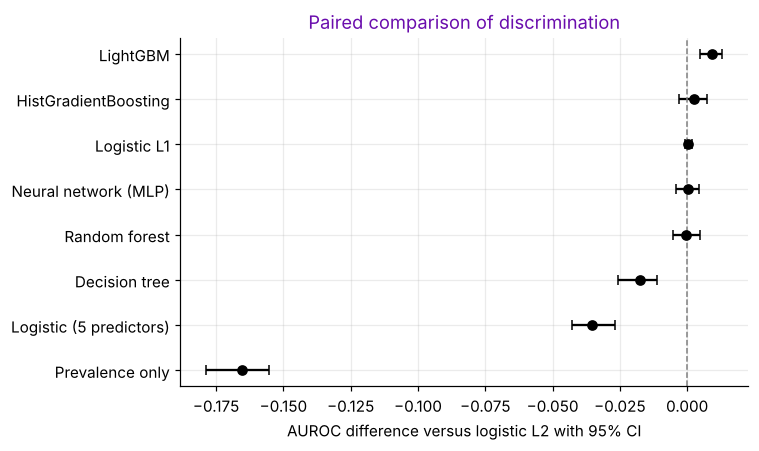

In [21]:
ref = "Logistic L2"
rows = []
for n in MODEL_NAMES:
    if n == ref:
        continue
    d = boot_auc[n] - boot_auc[ref]
    p_val = min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean()))
    rows.append({"Model": n, "AUROC_difference": metrics.loc[n, "AUROC"] - metrics.loc[ref, "AUROC"],
                 "CI_low": ci95(d)[0], "CI_high": ci95(d)[1], "bootstrap_p": p_val})
diff_table = pd.DataFrame(rows).set_index("Model")
display(diff_table.round(4))
savetable(diff_table, "test_auroc_differences_vs_logistic_L2")

fig, ax = plt.subplots(figsize=(7, 4.2))
t = diff_table.sort_values("AUROC_difference")
yy = np.arange(len(t))
ax.errorbar(t["AUROC_difference"], yy, xerr=[t["AUROC_difference"] - t["CI_low"], t["CI_high"] - t["AUROC_difference"]], fmt="o", color="black", capsize=3)
ax.axvline(0, color="grey", ls="--", lw=1)
ax.set_yticks(yy)
ax.set_yticklabels(t.index)
ax.set_xlabel("AUROC difference versus logistic L2 with 95% CI")
ax.set_title("Paired comparison of discrimination")
savefig("11_auroc_differences")

**What this shows (RQ4).** Each point is the AUROC difference from L2 logistic regression with a 95 percent paired bootstrap interval. LightGBM is better by 0.0091 (0.0047 to 0.0130). L1 logistic, random forest, HistGradientBoosting and the neural network are statistically indistinguishable from L2 logistic (differences between minus 0.001 and plus 0.003 with intervals that include zero). The five-predictor model (minus 0.036) and the decision tree (minus 0.018) are clearly worse.

**Why it matters for the research.** H4 is supported. Gradient boosting helps only slightly. A gain of 0.009 is statistically detectable but small, so a simple regularised logistic model is a defensible choice when transparency matters.

<h3 style="color:#6A0DAD;">11.2 Discrimination plots</h3>

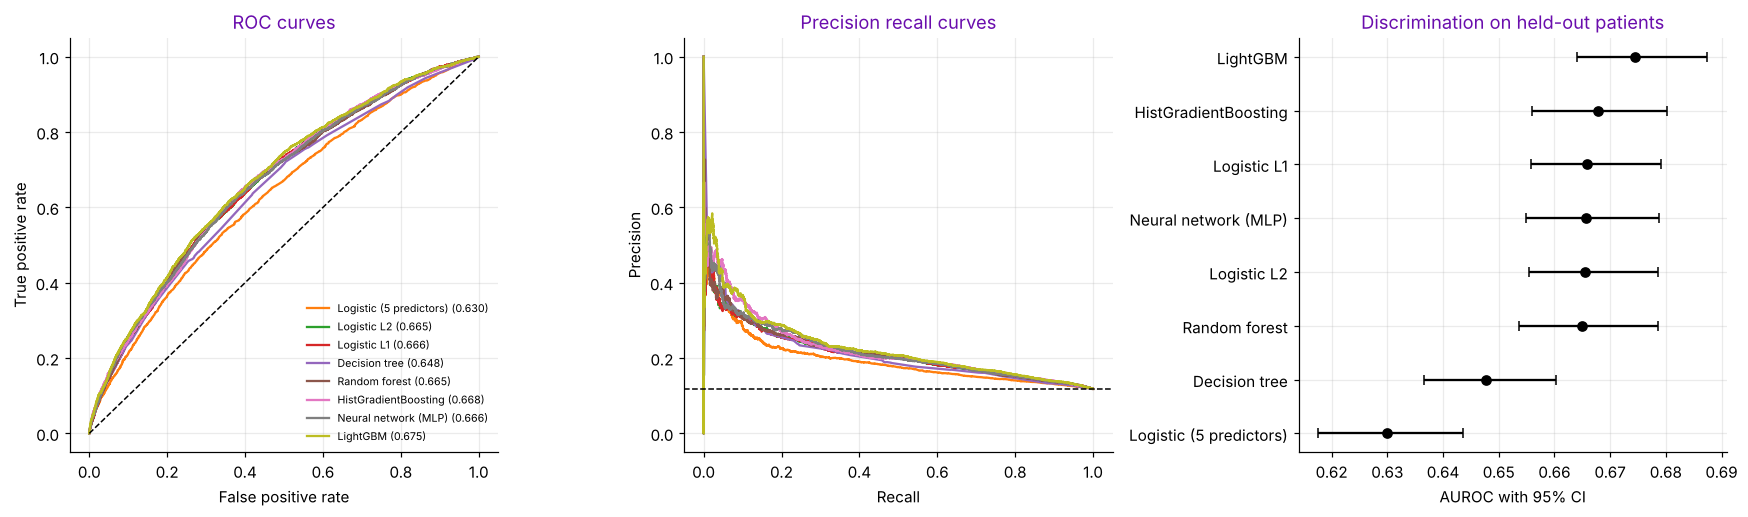

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
colors = plt.get_cmap("tab10")(np.linspace(0, 1, 10))
for c, n in zip(colors, MODEL_NAMES):
    if n == "Prevalence only":
        continue
    fpr, tpr, _ = roc_curve(yt, PRED[n]["test"])
    axes[0].plot(fpr, tpr, color=c, label=f"{n} ({metrics.loc[n, 'AUROC']:.3f})")
    prec, rec, _ = precision_recall_curve(yt, PRED[n]["test"])
    axes[1].plot(rec, prec, color=c, label=n)
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curves")
axes[0].legend(frameon=False, fontsize=7)
axes[1].axhline(yt.mean(), color="k", ls="--", lw=1)
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision recall curves")

order = metrics["AUROC"].drop("Prevalence only").sort_values()
lo_hi = np.array([ci95(boot_auc[n]) for n in order.index])
yy = np.arange(len(order))
axes[2].errorbar(order.values, yy, xerr=[order.values - lo_hi[:, 0], lo_hi[:, 1] - order.values], fmt="o", color="black", capsize=3)
axes[2].set_yticks(yy)
axes[2].set_yticklabels(order.index)
axes[2].set_xlabel("AUROC with 95% CI")
axes[2].set_title("Discrimination on held-out patients")
savefig("12_discrimination")

**What this shows.** On the left the ROC curves for the models sit close together and well above the diagonal but far from the top left corner. In the middle the precision recall curves start high at very low recall and settle around 0.2 to 0.3, always above the dashed prevalence line (0.118). On the right the dot and whisker plot orders models by AUROC and the intervals of the top seven overlap.

**Why it matters for the research.** The model can rank patients usefully but cannot identify readmissions with high precision. Any practical use would be to prioritise follow-up and not to make firm individual predictions.

<h3 style="color:#6A0DAD;">11.3 Calibration plots</h3>

Each panel shows observed readmission against mean predicted risk in ten equal-sized risk groups. Points on the dashed line mean perfect calibration. The grey histogram at the bottom shows how predictions are spread.

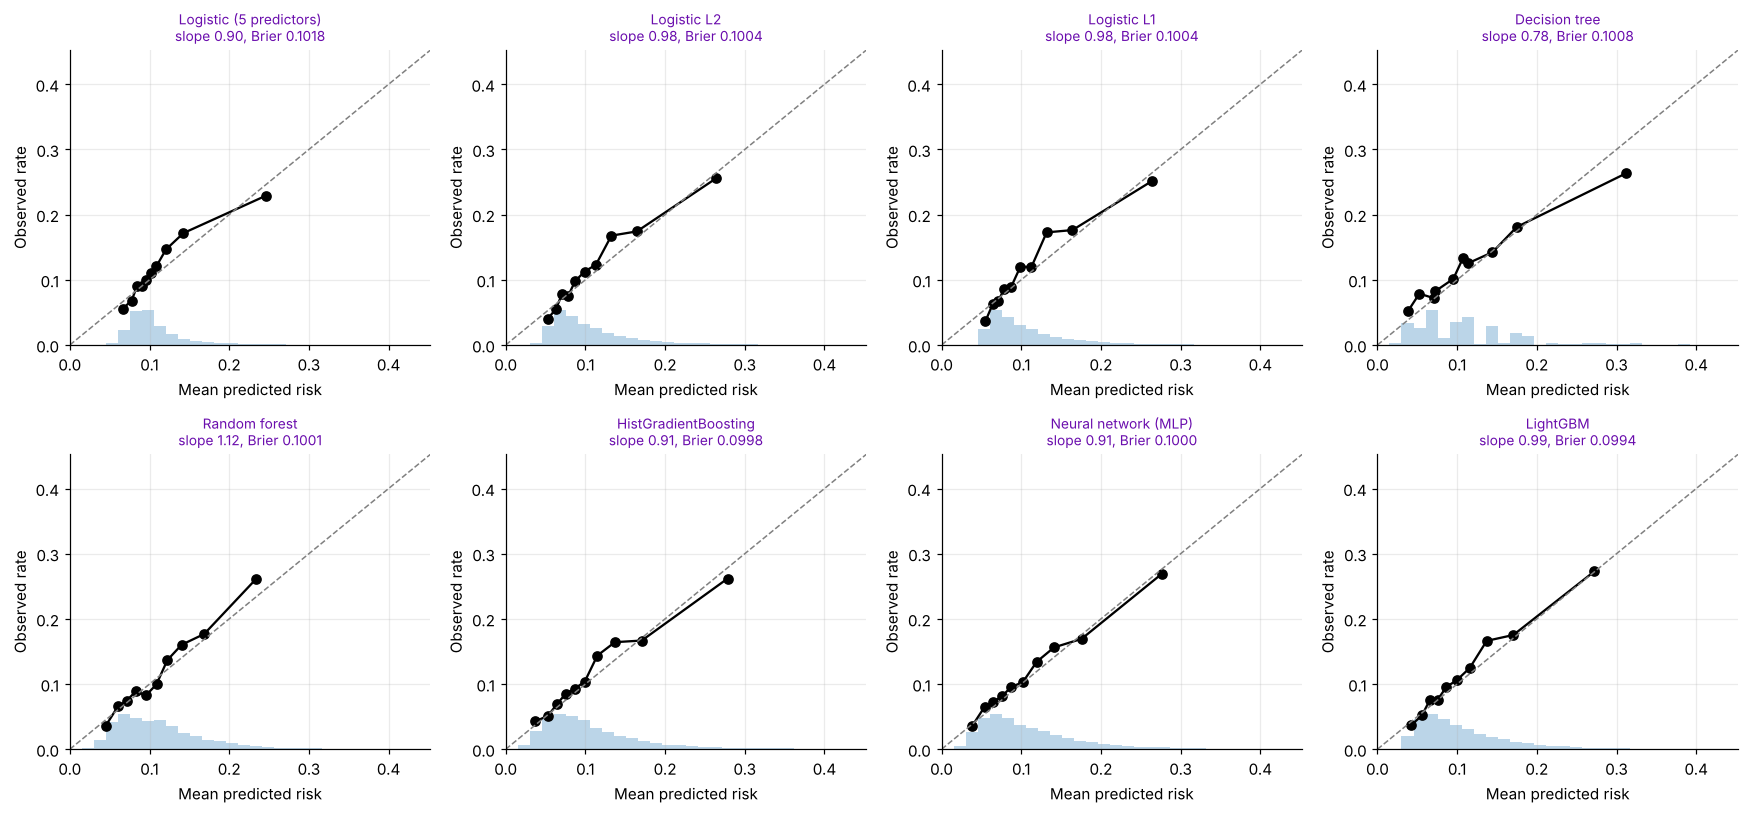

In [23]:
plot_models = [n for n in MODEL_NAMES if n != "Prevalence only"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
lim = max(0.3, float(np.quantile(np.concatenate([PRED[n]["test"] for n in plot_models]), 0.995)))
for ax, n in zip(axes.ravel(), plot_models):
    p = PRED[n]["test"]
    frac, mean = calibration_curve(yt, p, n_bins=10, strategy="quantile")
    ax.plot(mean, frac, "o-", color="black")
    ax.plot([0, lim], [0, lim], "--", color="grey", lw=1)
    counts, edges = np.histogram(p, bins=30, range=(0, lim))
    ax.bar(edges[:-1], counts / max(counts.max(), 1) * 0.12 * lim, width=np.diff(edges), align="edge", color="tab:blue", alpha=0.3)
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)
    ax.set_title(f"{n}\nslope {metrics.loc[n, 'slope']:.2f}, Brier {metrics.loc[n, 'Brier']:.4f}", fontsize=9)
    ax.set_xlabel("Mean predicted risk")
    ax.set_ylabel("Observed rate")
savefig("13_calibration_all_models")

**What this shows (RQ5).** Each panel compares predicted and observed risk in ten equal-sized groups. Points on the dashed line are perfectly calibrated. Most patients receive predictions between 0.03 and 0.20 (blue histogram). All curves follow the diagonal closely but lie slightly above it in the middle and upper ranges, which means observed readmission was a little higher than predicted. This matches the positive calibration-in-the-large. The single decision tree is the least tidy with only a few distinct risk levels and the lowest slope (0.78).

**Why it matters for the research.** H5 is not supported. LightGBM and the neural network have the lowest ECE (0.008), better than logistic regression (0.012), so the flexible models were not worse calibrated than the simple ones.

<h2 style="color:#6A0DAD;">12. Recalibration (RQ5)</h2>

Platt scaling fits a logistic curve to the model score (Platt, 1999) and isotonic regression fits a monotone step function (Zadrozny and Elkan, 2002). Both are fitted on the separate calibration set and then evaluated on the test set. Platt scaling is monotone so it leaves AUROC unchanged. Isotonic regression can slightly change ranking because it creates tied scores.

AUROC   Brier   slope    citl     ECE
Model                   Variant                                         
Logistic (5 predictors) raw       0.6299  0.1018  0.8985  0.0509  0.0124
                        Platt     0.6299  0.1017  0.9851  0.0308  0.0103
                        isotonic  0.6286  0.1015  0.9306  0.0364  0.0062
Logistic L2             raw       0.6655  0.1004  0.9753  0.0569  0.0119
                        Platt     0.6655  0.1003  1.0420  0.0395  0.0109
                        isotonic  0.6643  0.1004  0.9510  0.0398  0.0072
Logistic L1             raw       0.6658  0.1004  0.9782  0.0551  0.0126
                        Platt     0.6658  0.1004  1.0348  0.0384  0.0120
                        isotonic  0.6633  0.1004  0.9478  0.0401  0.0097
Decision tree           raw       0.6478  0.1008  0.7819  0.0545  0.0117
                        Platt     0.6478  0.1006  1.0154  0.0343  0.0075
                        isotonic  0.6474  0.1006  0.9806  0.0347  0.0065
Random forest           raw       0.6649  0.1001  1.1168  0.0540  0.0116
                        Platt     0.6649  0.1000  1.0054  0.0384  0.0088
                        isotonic  0.6632  0.1003  0.8981  0.0350  0.0066
HistGradientBoosting    raw       0.6679  0.0998  0.9078  0.0673  0.0109
                        Platt     0.6679  0.0997  0.9791  0.0408  0.0076
                        isotonic  0.6670  0.0998  0.9292  0.0425  0.0092
Neural network (MLP)    raw       0.6657  0.1000  0.9109  0.0486  0.0079
                        Platt     0.6657  0.0999  1.0568  0.0358  0.0066
                        isotonic  0.6648  0.1003  0.8008  0.0307  0.0054
LightGBM                raw       0.6745  0.0994  0.9904  0.0619  0.0079
                        Platt     0.6745  0.0994  1.0117  0.0349  0.0068
                        isotonic  0.6734  0.0995  0.8957  0.0326  0.0069

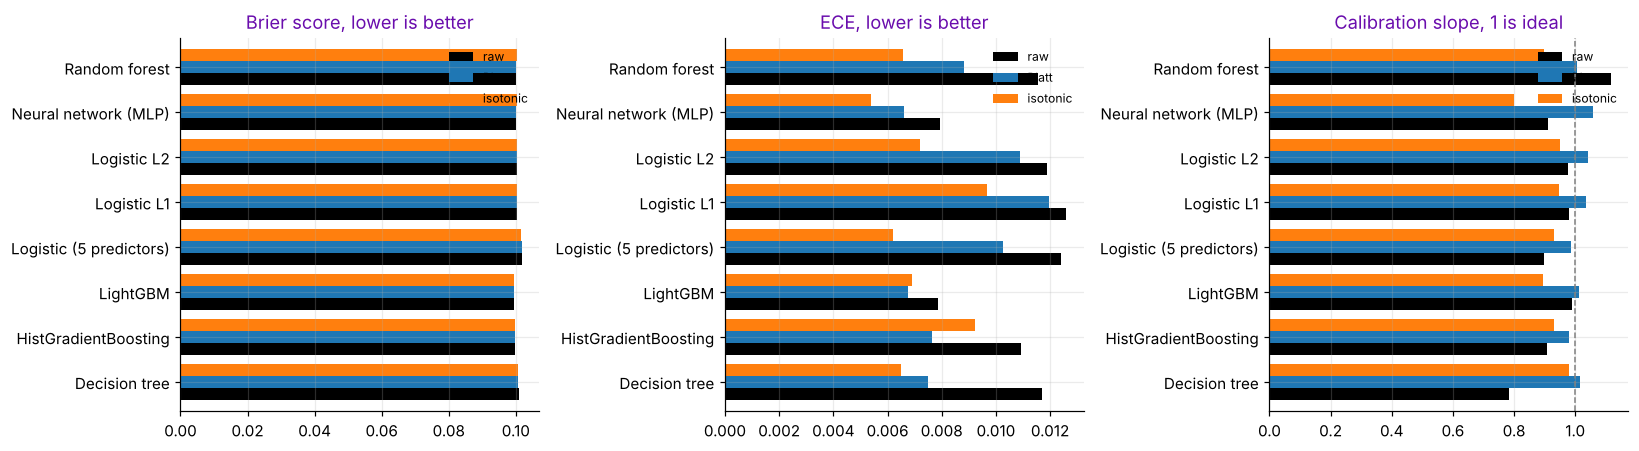

In [24]:
class Platt:
    def fit(self, p, yv):
        self.m = LogisticRegression(C=1e6, max_iter=1000).fit(logit(p)[:, None], yv)
        return self

    def predict(self, p):
        return self.m.predict_proba(logit(p)[:, None])[:, 1]


class Isotonic:
    def fit(self, p, yv):
        self.m = IsotonicRegression(out_of_bounds="clip", y_min=1e-4, y_max=1 - 1e-4).fit(p, yv)
        return self

    def predict(self, p):
        return self.m.predict(p)


CAL_PRED = {}
rows = []
for n in MODEL_NAMES:
    if n == "Prevalence only":
        continue
    variants = {"raw": PRED[n]["test"]}
    for label, cls in [("Platt", Platt), ("isotonic", Isotonic)]:
        cal = cls().fit(PRED[n]["calib"], Y["calib"])
        variants[label] = cal.predict(PRED[n]["test"])
        CAL_PRED[(n, label)] = {"calib_obj": cal, "test": variants[label]}
    for label, p in variants.items():
        r = full_metrics(yt, p, codes_test)
        rows.append({"Model": n, "Variant": label, **r})
recal = pd.DataFrame(rows).set_index(["Model", "Variant"])
display(recal[["AUROC", "Brier", "slope", "citl", "ECE"]].round(4))
savetable(recal, "test_metrics_recalibration")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, metric, title in zip(axes, ["Brier", "ECE", "slope"], ["Brier score, lower is better", "ECE, lower is better", "Calibration slope, 1 is ideal"]):
    wide = recal[metric].unstack("Variant")[["raw", "Platt", "isotonic"]]
    wide.plot.barh(ax=ax, color=["black", "tab:blue", "tab:orange"], width=0.8)
    if metric == "slope":
        ax.axvline(1, color="grey", ls="--", lw=1)
    ax.set_title(title)
    ax.set_ylabel("")
    ax.legend(frameon=False, fontsize=8)
savefig("14_recalibration_effect")

**What this shows (RQ5).** The bars compare uncalibrated predictions with Platt scaling and isotonic regression. Platt scaling leaves AUROC unchanged, moves the calibration slopes close to 1 for most models and reduces calibration-in-the-large from about 0.05 to 0.07 down to about 0.03 to 0.04. Isotonic regression gives similar ECE but changes AUROC slightly and gives less stable slopes (for example 0.90 for LightGBM against 1.01 with Platt).

**Why it matters for the research.** Recalibration helps modestly. It cannot remove the remaining offset because the offset comes from the test set having a higher readmission rate (11.82 percent) than the calibration set (11.39 percent). It is a reminder that calibration should be checked again whenever a model is used in a population with a different baseline rate.

Best model by validation AUROC: LightGBM


Brier improvement from Platt scaling 0.00003, 95% CI 0.00001 to 0.00005


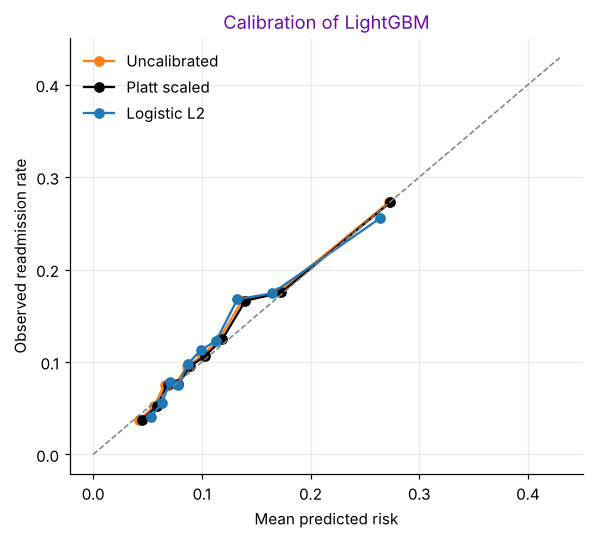

In [25]:
# Paired bootstrap for the Brier score improvement from Platt scaling of the best model by validation AUROC
best_name = max([n for n in MODEL_NAMES if n != "Prevalence only"], key=lambda n: RESULTS[n]["val_auc"])
print("Best model by validation AUROC:", best_name)
p_raw = PRED[best_name]["test"]
p_platt = CAL_PRED[(best_name, "Platt")]["test"]
d = []
for idx in DRAWS:
    if yt[idx].min() == yt[idx].max():
        continue
    d.append(brier_score_loss(yt[idx], p_raw[idx]) - brier_score_loss(yt[idx], p_platt[idx]))
d = np.array(d)
print(f"Brier improvement from Platt scaling {d.mean():.5f}, 95% CI {ci95(d)[0]:.5f} to {ci95(d)[1]:.5f}")

fig, ax = plt.subplots(figsize=(5.5, 5))
lim = max(0.3, float(np.quantile(p_raw, 0.995)))
for label, p, c in [("Uncalibrated", p_raw, "tab:orange"), ("Platt scaled", p_platt, "black"),
                    ("Logistic L2", PRED["Logistic L2"]["test"], "tab:blue")]:
    frac, mean = calibration_curve(yt, p, n_bins=10, strategy="quantile")
    ax.plot(mean, frac, "o-", color=c, label=label)
ax.plot([0, lim], [0, lim], "--", color="grey", lw=1)
ax.set_xlabel("Mean predicted risk")
ax.set_ylabel("Observed readmission rate")
ax.set_title(f"Calibration of {best_name}")
ax.legend(frameon=False)
savefig("15_calibration_best_model")

**What this shows.** For LightGBM the uncalibrated, Platt scaled and logistic regression curves nearly coincide and hug the diagonal. The Brier improvement from Platt scaling is 0.00003 (95 percent interval 0.00001 to 0.00005).

**Why it matters for the research.** The improvement is statistically positive but practically negligible. LightGBM was already well calibrated, so Platt scaling is optional here. It is kept in the pipeline because it is cheap and protects against miscalibration in other models.

<h2 style="color:#6A0DAD;">13. Interpretability</h2>

SHAP values (Lundberg and Lee, 2017) from the tree explainer (Lundberg et al., 2020) show how much each feature moves the predicted log-odds of readmission for the LightGBM model. The bar chart ranks features by mean absolute contribution. The dot plot shows direction for numeric features only. The right panel shows how the contribution changes with prior inpatient visits. SHAP describes what the model uses and does not show causes.

,mean_abs_shap
number_inpatient,0.2191
discharge_disposition_id,0.1750
prior_visits_total,0.0878
diag_1_grp,0.0693
age_mid,0.0603
number_diagnoses,0.0512
medical_specialty,0.0467
diag_3_grp,0.0404
diag_2_grp,0.0396
num_medications,0.0358


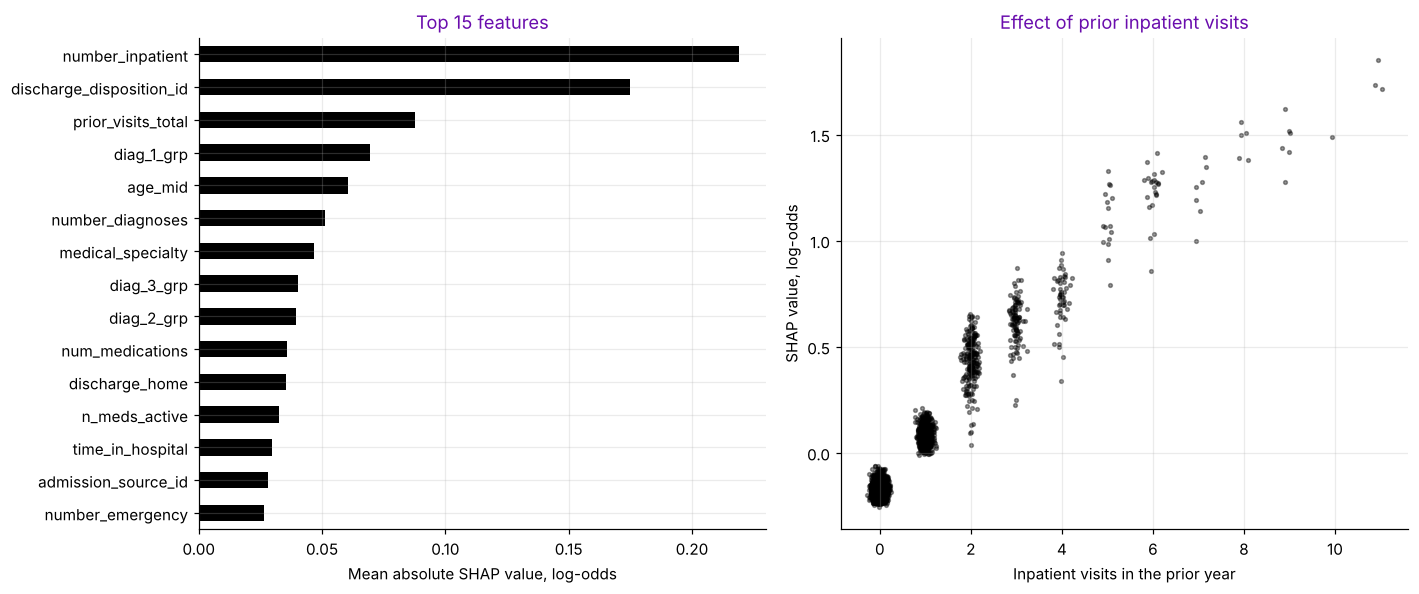

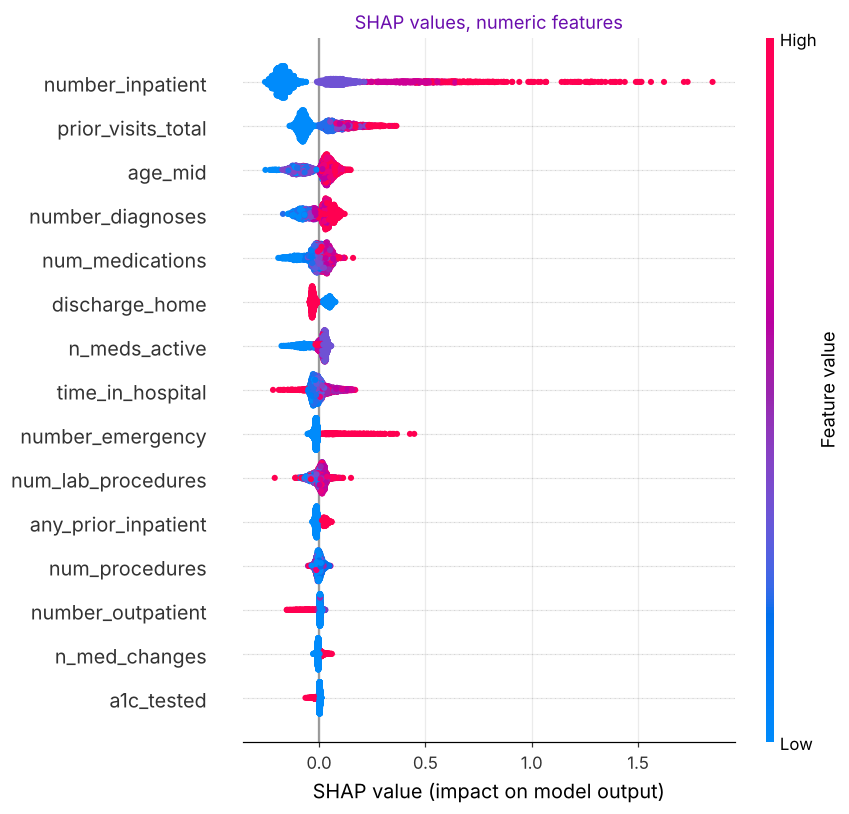

In [26]:
lgb_model = RESULTS["LightGBM"]["model"]
sample = XL["test"].sample(min(3000, len(XL["test"])), random_state=SEED)
# LightGBM computes exact TreeSHAP values itself. The last column is the baseline value and is dropped.
sv = np.asarray(lgb_model.predict(sample, pred_contrib=True))[:, :-1]
imp = pd.Series(np.abs(sv).mean(axis=0), index=sample.columns).sort_values(ascending=False)
savetable(imp.to_frame("mean_abs_shap"), "shap_mean_abs")
display(imp.head(15).round(4).to_frame("mean_abs_shap"))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
imp.head(15)[::-1].plot.barh(ax=axes[0], color="black")
axes[0].set_xlabel("Mean absolute SHAP value, log-odds")
axes[0].set_title("Top 15 features")
j = list(sample.columns).index("number_inpatient")
jitter = np.random.default_rng(SEED).normal(0, 0.08, len(sample))
axes[1].scatter(sample["number_inpatient"].values + jitter, sv[:, j], s=6, alpha=0.4, color="black")
axes[1].set_xlabel("Inpatient visits in the prior year")
axes[1].set_ylabel("SHAP value, log-odds")
axes[1].set_title("Effect of prior inpatient visits")
savefig("16_shap_summary")

numeric_cols = NUM_MODEL + FLAG_MODEL
ix = [list(sample.columns).index(c) for c in numeric_cols]
if shap is not None:
    try:
        shap.summary_plot(sv[:, ix], sample[numeric_cols], show=False, max_display=15)
        plt.title("SHAP values, numeric features")
        savefig("17_shap_beeswarm_numeric")
    except Exception as exc:
        plt.close("all")
        print("Dot plot skipped:", exc)
else:
    print("The shap package is not installed so the dot plot was skipped")

**What this shows (RQ1, RQ2).** The bar chart ranks features by mean absolute SHAP value, which is the average push each feature gives to the predicted log-odds. Prior inpatient visits lead (0.219), followed by discharge disposition (0.175), total prior visits (0.088), primary diagnosis group (0.069), age (0.060), number of diagnoses (0.051) and medical specialty (0.047). The right panel shows the effect of prior inpatient visits. The contribution rises steadily from about minus 0.2 for no visits to about plus 0.5 for two, plus 1.5 for eight and close to plus 1.8 for the highest counts. The dot plot shows direction for numeric features. High emergency visit counts raise risk, discharge to home lowers it, higher age and more diagnoses raise it, and HbA1c measurement lowers it slightly. High outpatient visit counts lower predicted risk, a pattern that was not visible in the logistic model and deserves caution.

**Why it matters for the research.** The explanation agrees with the statistics. Prior inpatient use and discharge destination dominate in the tests, the regression and the model. SHAP shows what the model uses and does not show causes.

<h2 style="color:#6A0DAD;">14. Subgroup analysis (RQ6)</h2>

Discrimination and calibration for the best model after Platt scaling, split by sex, age band and race. Intervals come from the same patient-clustered resamples. A model can look fine overall and still perform worse for some groups. Race is used here only to check performance and is not a recommended input for decisions.

n  readmission_rate  AUROC  AUROC_lo  AUROC_hi  \
variable group                                                                 
gender   Female           10829             0.117  0.670     0.653     0.691   
         Male              9143             0.119  0.680     0.662     0.695   
age_band 50-69             7783             0.112  0.685     0.665     0.705   
         70+               8931             0.124  0.642     0.625     0.660   
         <50               3258             0.117  0.725     0.688     0.755   
race     AfricanAmerican   3677             0.124  0.666     0.638     0.693   
         Caucasian        15018             0.118  0.671     0.659     0.685   

                          calibration_slope  observed_to_expected  
variable group                                                     
gender   Female                       0.978                 1.000  
         Male                         1.060                 1.066  
age_band 50-69                        1.048                 1.034  
         70+                          0.977                 1.011  
         <50                          1.006                 1.080  
race     AfricanAmerican              0.919                 1.093  
         Caucasian                    1.010                 1.020

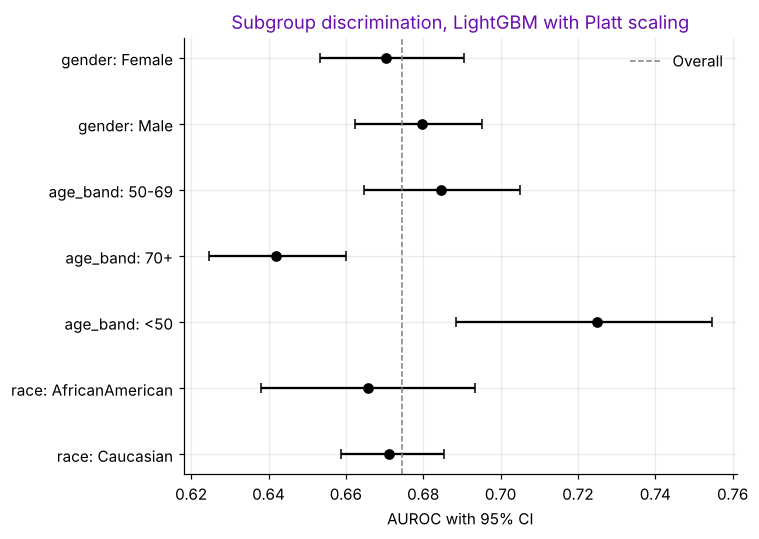

AUROC difference male minus female 0.0082, 95% CI -0.0152 to 0.0324


In [27]:
final_p = CAL_PRED[(best_name, "Platt")]["test"]
test_df = df.loc[m["test"]].reset_index(drop=True)
sub_rows = []
for var in ["gender", "age_band", "race"]:
    for level in sorted(test_df[var].unique()):
        mask = (test_df[var] == level).values
        if mask.sum() < 500 or yt[mask].min() == yt[mask].max():
            continue
        aucs = []
        for idx in DRAWS:
            sel = idx[mask[idx]]
            if len(sel) > 100 and yt[sel].min() != yt[sel].max():
                aucs.append(roc_auc_score(yt[sel], final_p[sel]))
        aucs = np.array(aucs)
        cs = calib_stats(yt[mask], final_p[mask], codes_test[mask])
        sub_rows.append({"variable": var, "group": level, "n": int(mask.sum()), "readmission_rate": yt[mask].mean(),
                         "AUROC": roc_auc_score(yt[mask], final_p[mask]), "AUROC_lo": ci95(aucs)[0], "AUROC_hi": ci95(aucs)[1],
                         "calibration_slope": cs["slope"], "observed_to_expected": yt[mask].mean() / final_p[mask].mean()})
sub = pd.DataFrame(sub_rows).set_index(["variable", "group"])
display(sub.round(3))
savetable(sub, "subgroup_results")

fig, ax = plt.subplots(figsize=(7, 5))
t = sub.reset_index()
yy = np.arange(len(t))
ax.errorbar(t["AUROC"], yy, xerr=[t["AUROC"] - t["AUROC_lo"], t["AUROC_hi"] - t["AUROC"]], fmt="o", color="black", capsize=3)
ax.axvline(roc_auc_score(yt, final_p), color="grey", ls="--", lw=1, label="Overall")
ax.set_yticks(yy)
ax.set_yticklabels([f"{a}: {b}" for a, b in zip(t["variable"], t["group"])])
ax.invert_yaxis()
ax.set_xlabel("AUROC with 95% CI")
ax.set_title(f"Subgroup discrimination, {best_name} with Platt scaling")
ax.legend(frameon=False)
savefig("18_subgroup_auroc")

if "gender" in sub.index.get_level_values(0):
    male = (test_df["gender"] == "Male").values
    dif = []
    for idx in DRAWS:
        a, b = idx[male[idx]], idx[~male[idx]]
        if len(a) > 100 and len(b) > 100 and yt[a].min() != yt[a].max() and yt[b].min() != yt[b].max():
            dif.append(roc_auc_score(yt[a], final_p[a]) - roc_auc_score(yt[b], final_p[b]))
    dif = np.array(dif)
    print(f"AUROC difference male minus female {dif.mean():.4f}, 95% CI {ci95(dif)[0]:.4f} to {ci95(dif)[1]:.4f}")

**What this shows (RQ6).** The table and plot give discrimination and calibration for the best model after Platt scaling. AUROC is 0.670 for women and 0.680 for men and the difference is 0.0082 (95 percent interval minus 0.0152 to 0.0324), so there is no evidence of a sex difference. By age, discrimination falls from 0.725 under 50 to 0.685 at 50 to 69 and 0.642 at 70 and over. The intervals for under 50 (0.688 to 0.755) and 70 and over (0.625 to 0.660) do not overlap. For race, AUROC is 0.666 for African American and 0.671 for Caucasian patients. Other race groups had fewer than 500 test encounters and were left out. Calibration slopes are between 0.92 and 1.06 and observed to expected ratios between 1.00 and 1.09, so risk is slightly underestimated in most groups, which matches the overall pattern.

**Why it matters for the research.** The model is equally accurate for women and men and across the two largest race groups, but it ranks older patients less well. This is a limitation to report when considering any deployment, and the small race groups remain unassessed.

<h2 style="color:#6A0DAD;">15. Decision curve analysis (RQ7)</h2>

Decision curve analysis asks whether acting on the model improves decisions across a range of risk thresholds (Vickers and Elkin, 2006). Net benefit is the true positives per patient minus the false positives per patient weighted by the odds of the threshold. A model is useful at thresholds where its curve lies above both treating everyone and treating no one. The table converts the gain over treating everyone into follow-up interventions avoided per 100 patients.

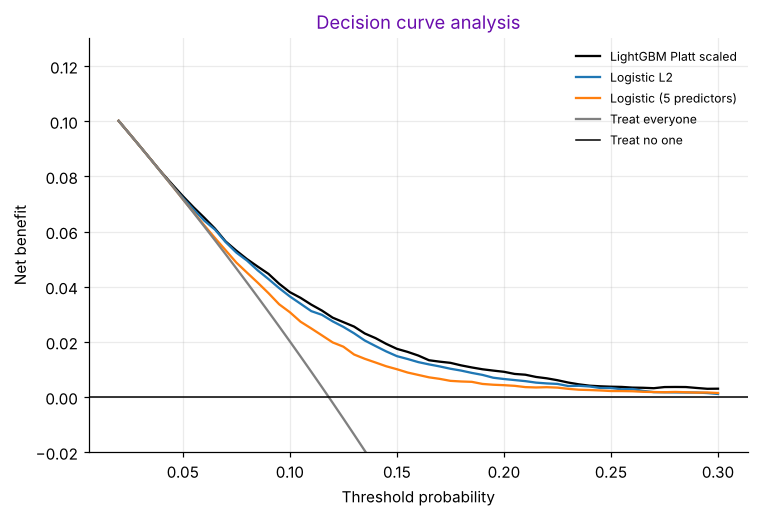

,net_benefit_model,net_benefit_treat_all,interventions_avoided_per_100
threshold,,,
0.08,0.0500,0.0415,9.7962
0.10,0.0380,0.0202,16.0725
0.12,0.0288,-0.0021,22.6400
0.15,0.0175,-0.0375,31.1336
0.20,0.0092,-0.1023,44.5824


In [28]:
def net_benefit(yv, p, thresholds):
    n = len(yv)
    out = []
    for t_ in thresholds:
        pred = p >= t_
        tp, fp = (pred & (yv == 1)).sum(), (pred & (yv == 0)).sum()
        out.append(tp / n - fp / n * t_ / (1 - t_))
    return np.array(out)


thr = np.linspace(0.02, 0.30, 57)
curves = {f"{best_name} Platt scaled": final_p, "Logistic L2": PRED["Logistic L2"]["test"],
          "Logistic (5 predictors)": PRED["Logistic (5 predictors)"]["test"]}
fig, ax = plt.subplots(figsize=(7, 4.8))
for (label, p), c in zip(curves.items(), ["black", "tab:blue", "tab:orange"]):
    ax.plot(thr, net_benefit(yt, p, thr), label=label, color=c)
nb_all = net_benefit(yt, np.ones(len(yt)), thr)
ax.plot(thr, nb_all, color="grey", label="Treat everyone")
ax.axhline(0, color="k", lw=1, label="Treat no one")
top = max(float(net_benefit(yt, p, thr).max()) for p in curves.values())
ax.set_ylim(-0.02, max(0.03, top * 1.3))
ax.set_xlabel("Threshold probability")
ax.set_ylabel("Net benefit")
ax.set_title("Decision curve analysis")
ax.legend(frameon=False, fontsize=8)
savefig("19_decision_curve")

rows = []
for t_ in [0.08, 0.10, 0.12, 0.15, 0.20]:
    nb_model = net_benefit(yt, final_p, [t_])[0]
    nb_treat = net_benefit(yt, np.ones(len(yt)), [t_])[0]
    rows.append({"threshold": t_, "net_benefit_model": nb_model, "net_benefit_treat_all": nb_treat,
                 "interventions_avoided_per_100": (nb_model - nb_treat) / (t_ / (1 - t_)) * 100})
dca_table = pd.DataFrame(rows).set_index("threshold")
display(dca_table.round(4))
savetable(dca_table, "decision_curve_table")

**What this shows (RQ7).** The grey line treats every patient as high risk and the horizontal line treats no one. From a threshold of about 5 percent up to 30 percent the LightGBM curve lies at or above both and above the five-predictor model, while the full logistic model sits very close to LightGBM. At a 10 percent threshold the net benefit is 0.038 against 0.020 for treating everyone, which equals 16 unnecessary follow-ups avoided per 100 patients without missing readmissions. At 15 percent it is 31 per 100 and at 20 percent 45 per 100. At a threshold of 8 percent the gain is smaller (about 10 per 100) and below about 5 percent the model adds almost nothing over treating everyone.

**Why it matters for the research.** Acting on the model would add value if an unnecessary follow-up costs between about a quarter and a ninth of what a missed readmission is worth, which corresponds to thresholds of 20 and 10 percent. The curves for LightGBM and logistic regression are almost the same, so the benefit comes from the information in the features and not from the complexity of the algorithm.

<h2 style="color:#6A0DAD;">16. Leakage experiment (RQ3)</h2>

The same hyperparameters are used for logistic regression and LightGBM on two different splits. The first assigns whole patients to a set, as in the main analysis. The second assigns single encounters at random so the same patient can appear in train and test. The difference in test AUROC measures how much a naive split overstates performance (Kapoor and Narayanan, 2023). Both test sets use patient-clustered bootstrap intervals. The difference interval treats the two test sets as independent so it is approximate.

Share of random-split test rows whose patient also appears in training: 35.7%


,Model,Split,AUROC,CI_low,CI_high
0,Logistic L2,Patient-level split,0.6655,0.6554,0.6786
1,Logistic L2,Encounter-level random split,0.6575,0.6480,0.6682
2,LightGBM,Patient-level split,0.6745,0.6616,0.6860
3,LightGBM,Encounter-level random split,0.6682,0.6568,0.6812


,Model,AUROC_inflation,CI_low,CI_high
0,Logistic L2,-0.0079,-0.0219,0.0081
1,LightGBM,-0.0063,-0.0226,0.0116


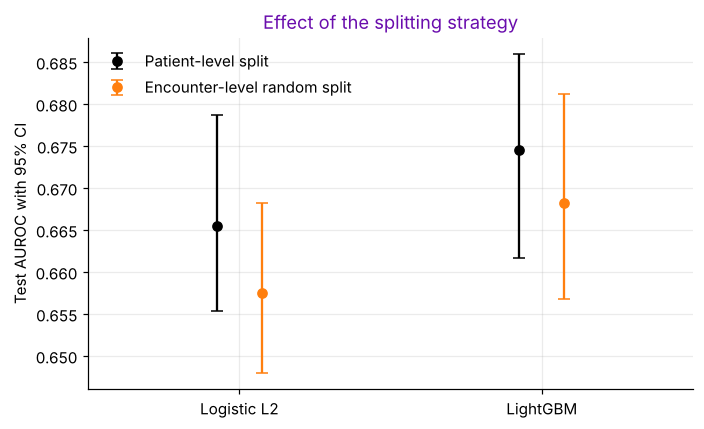

In [29]:
rand_split = assign_split(np.arange(len(df)))
rm = {s: rand_split == s for s in SPLITS}
overlap = float(np.isin(pid[rm["test"]], pid[rm["train"]]).mean())
print(f"Share of random-split test rows whose patient also appears in training: {overlap:.1%}")


def eval_split(masks, label):
    tr, va, te = masks["train"], masks["val"], masks["test"]
    prep = make_prep(NUM_MODEL + FLAG_MODEL, CAT_MODEL).fit(X[tr])
    lr = LogisticRegression(C=RESULTS["Logistic L2"]["params"]["C"], max_iter=3000).fit(prep.transform(X[tr]), y[tr])
    p_lr = lr.predict_proba(prep.transform(X[te]))[:, 1]
    g = lgb.LGBMClassifier(n_estimators=3000, learning_rate=0.03, num_leaves=RESULTS["LightGBM"]["params"]["leaves"], min_child_samples=50,
                           subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=5.0, random_state=SEED, verbose=-1)
    g.fit(Xl[tr], y[tr], eval_set=[(Xl[va], y[va])], eval_metric="auc", callbacks=[lgb.early_stopping(100, verbose=False)])
    p_gb = g.predict_proba(Xl[te])[:, 1]
    yy_ = y[te]
    rows_ = list(pd.Series(np.arange(len(yy_))).groupby(pd.factorize(pid[te])[0]).indices.values())
    rng = np.random.default_rng(SEED)
    res = {}
    for name, p in [("Logistic L2", p_lr), ("LightGBM", p_gb)]:
        boots = []
        for _ in range(N_BOOT):
            pick = rng.integers(0, len(rows_), len(rows_))
            idx = np.concatenate([rows_[i] for i in pick])
            if yy_[idx].min() != yy_[idx].max():
                boots.append(roc_auc_score(yy_[idx], p[idx]))
        res[name] = (roc_auc_score(yy_, p), np.array(boots))
    return res


res_patient = eval_split(m, "patient")
res_random = eval_split(rm, "random")
rows = []
for name in ["Logistic L2", "LightGBM"]:
    for label, res in [("Patient-level split", res_patient), ("Encounter-level random split", res_random)]:
        a, b = res[name]
        rows.append({"Model": name, "Split": label, "AUROC": a, "CI_low": ci95(b)[0], "CI_high": ci95(b)[1]})
leak = pd.DataFrame(rows)
leak_diff = []
for name in ["Logistic L2", "LightGBM"]:
    dd = res_random[name][1][:min(len(res_random[name][1]), len(res_patient[name][1]))] - res_patient[name][1][:min(len(res_random[name][1]), len(res_patient[name][1]))]
    leak_diff.append({"Model": name, "AUROC_inflation": res_random[name][0] - res_patient[name][0], "CI_low": ci95(dd)[0], "CI_high": ci95(dd)[1]})
display(leak.round(4))
display(pd.DataFrame(leak_diff).round(4))
savetable(leak.set_index(["Model", "Split"]), "leakage_experiment")

fig, ax = plt.subplots(figsize=(6.5, 4))
for i, label in enumerate(["Patient-level split", "Encounter-level random split"]):
    t = leak[leak["Split"] == label]
    ax.errorbar(np.arange(2) + (i - 0.5) * 0.15, t["AUROC"], yerr=[t["AUROC"] - t["CI_low"], t["CI_high"] - t["AUROC"]],
                fmt="o", capsize=4, label=label, color=["black", "tab:orange"][i])
ax.set_xticks(np.arange(2))
ax.set_xticklabels(["Logistic L2", "LightGBM"])
ax.set_xlim(-0.5, 1.5)
ax.set_ylabel("Test AUROC with 95% CI")
ax.set_title("Effect of the splitting strategy")
ax.legend(frameon=False)
savefig("20_leakage_experiment")

**What this shows (RQ3, H3).** Under the encounter-level random split 35.7 percent of test rows belong to a patient who is also in the training data. Even so the test AUROC was not higher than under the patient-level split. For LightGBM it was 0.6682 against 0.6745 and for logistic regression 0.6575 against 0.6655. The estimated inflation is minus 0.0063 (95 percent interval minus 0.0226 to 0.0116) for LightGBM and minus 0.0079 (minus 0.0219 to 0.0081) for logistic regression.

**Why it matters for the research.** H3 is not supported. No inflation was detected. A likely reason is that the features contain no patient identifier and mostly describe the current visit, so the models have little way to recognise repeat patients. The intervals are about plus or minus 0.02 wide so a small effect cannot be ruled out. The patient-level split therefore stays as a safeguard, but this dataset does not demonstrate a large leakage effect and the result should be reported as it is.

<h2 style="color:#6A0DAD;">17. Findings and limitations</h2>

<h3 style="color:#6A0DAD;">Answers to the research questions</h3>

| Question | Answer from this analysis |
|---|---|
| RQ1 Rates and groups | The overall 30-day readmission rate is 11.39 percent. It rises steeply with prior inpatient visits (8.6 to 26.4 percent) and is higher after discharge to places other than home (14.6 against 9.3 percent). Sex and race differ little. |
| RQ2 Adjusted associations and HbA1c | Prior inpatient visits (odds ratio 1.30 per visit), discharge home (0.67), diabetes medication (1.19) and HbA1c measurement (0.87) are the clearest adjusted associations. The HbA1c association differs by primary diagnosis (interaction p 0.0034). All effects are small and the regression explains little (pseudo R-squared 0.042). |
| RQ3 Leakage | A random encounter-level split put 35.7 percent of test rows in contact with training patients but did not raise AUROC. No inflation was detected, with intervals wide enough to allow a small one. |
| RQ4 Model comparison | LightGBM discriminates best (AUROC 0.6745) and is 0.009 better than L2 logistic regression. Other flexible models are not distinguishable from logistic regression. |
| RQ5 Calibration | All models are reasonably calibrated. A small underestimate of risk (calibration-in-the-large 0.05 to 0.07) comes from the higher readmission rate in the test set. Platt scaling helps slightly. |
| RQ6 Subgroups | No sex difference. Discrimination is lower for patients aged 70 and over (0.642) than under 50 (0.725). The two largest race groups perform alike. |
| RQ7 Decision curve | The model has net benefit above treat all and treat none from about 5 to 30 percent thresholds, for example 16 follow-ups avoided per 100 patients at 10 percent. |

<h3 style="color:#6A0DAD;">Verdict on the hypotheses</h3>

- H1 Prior inpatient visits are the strongest factor. **Largely supported.** They lead the SHAP ranking, the regression dose-response and the rate gradient. Discharge destination is a close competitor and has the largest chi-square effect size.
- H2 The HbA1c association differs by primary diagnosis. **Supported.** The interaction test is significant.
- H3 A naive split inflates AUROC. **Not supported.** No inflation was detected.
- H4 Gradient boosting improves only slightly on regularised logistic regression. **Supported.** LightGBM gains 0.009 and HistGradientBoosting gains nothing detectable.
- H5 Tree ensembles and neural networks are less well calibrated than logistic regression and recalibration closes the gap. **Not supported.** LightGBM and the neural network had the lowest ECE and the recalibration gains were small.

<h3 style="color:#6A0DAD;">How the results fit together</h3>

The exploratory analysis, the tests, the regression and the SHAP explanation all point to the same small set of drivers, namely prior inpatient use, discharge destination, age and diagnosis. Each carries a weak signal, which is why every model reaches only a modest AUROC of about 0.63 to 0.67 and why complex models gain little over simple ones. The models are well calibrated and offer net benefit at plausible thresholds, so they are useful for prioritising follow-up even though they cannot predict individual readmissions with confidence. Performance is lower for older patients and the leakage safeguard did not change the headline numbers on this dataset. Taken together the evidence supports using a transparent, well-calibrated model built on prior-use and discharge information, rather than a more complex algorithm.

<h3 style="color:#6A0DAD;">Limitations</h3>

- The data cover 1999 to 2008 in US hospitals so practice and populations have changed.
- There is no external validation and the test set comes from the same hospitals.
- Readmission is only observed within the same hospital system so some events are missed.
- Prior inpatient visits and similar features may not be available at discharge in every setting.
- The univariate tests use a single index encounter per patient and the choice of index encounter is a convention because the file has no dates.
- Many tests were run. Benjamini-Hochberg adjustment controls the false discovery rate within each family but not across families.
- Odds ratios and SHAP values describe associations and model behaviour, not causal effects.
- Race is used only to assess subgroup performance. Small race groups could not be assessed.
- The hyperparameter search was small and a wider search might change the order of close models.
- The leakage experiment compares two different test sets so its difference interval is approximate.
- The numbers in these notes come from one run with seed 42. A different library version can change the last decimal places.
- This is a research exercise and not a clinical tool.

<h2 style="color:#6A0DAD;">18. Reproducibility</h2>

In [30]:
versions = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "scipy": __import__("scipy").__version__, "statsmodels": statsmodels.__version__, "scikit-learn": sklearn.__version__,
            "lightgbm": lgb.__version__, "shap": shap.__version__, "seed": SEED, "bootstrap_resamples": N_BOOT, "fast_mode": FAST}
print(json.dumps(versions, indent=2))
(RES_DIR / "environment.json").write_text(json.dumps(versions, indent=2))

{
  "python": "3.12.3",
  "numpy": "2.5.4",
  "pandas": "3.0.6",
  "scipy": "1.18.1",
  "statsmodels": "0.15.0",
  "scikit-learn": "1.9.1",
  "lightgbm": "4.7.0",
  "shap": "0.54.1",
  "seed": 42,
  "bootstrap_resamples": 200,
  "fast_mode": false
}


249

<h3 style="color:#6A0DAD;">Project folders at the end of the run</h3>

In [31]:
for name, folder in FOLDERS.items():
    files = sorted(p.name for p in folder.iterdir() if p.is_file())
    print(f"{name} ({folder}): {len(files)} files")
    for f in files:
        print("   ", f)

data (/home/claude/real/data): 3 files
    analysis_cohort.csv.gz
    diabetic_data.csv
    split_assignment.csv
results (/home/claude/real/results): 16 files
    cohort_flow.json
    decision_curve_table.csv
    eda_rates_by_group.csv
    environment.json
    leakage_experiment.csv
    model_tuning.csv
    shap_mean_abs.csv
    split_summary.csv
    stats_a1c_by_diagnosis.csv
    stats_chi_square.csv
    stats_logistic_odds_ratios.csv
    stats_mann_whitney.csv
    subgroup_results.csv
    test_auroc_differences_vs_logistic_L2.csv
    test_metrics_recalibration.csv
    test_metrics_uncalibrated.csv
figures (/home/claude/real/figures): 20 files
    01_missingness.png
    02_encounters_per_patient.png
    03_rates_by_group.png
    04_numeric_distributions.png
    05_correlation_heatmap.png
    06_rate_by_patient_encounters.png
    07_cramers_v.png
    08_probability_of_superiority.png
    09_odds_ratio_forest.png
    10_a1c_by_diagnosis.png
    11_auroc_differences.png
    12_discrimina

<h2 style="color:#6A0DAD;">19. References</h2>

Benjamini, Y. and Hochberg, Y. (1995) 'Controlling the false discovery rate: a practical and powerful approach to multiple testing', *Journal of the Royal Statistical Society: Series B*, 57(1), pp. 289-300.

Breiman, L. (2001) 'Random forests', *Machine Learning*, 45(1), pp. 5-32.

Brier, G.W. (1950) 'Verification of forecasts expressed in terms of probability', *Monthly Weather Review*, 78(1), pp. 1-3.

Clore, J., Cios, K., DeShazo, J. and Strack, B. (2014) *Diabetes 130-US hospitals for years 1999-2008* [Dataset]. UCI Machine Learning Repository. Available at: https://doi.org/10.24432/C5230J

Collins, G.S. et al. (2024) 'TRIPOD+AI statement: updated guidance for reporting clinical prediction models that use regression or machine learning methods', *BMJ*, 385, e078378. Available at: https://doi.org/10.1136/bmj-2023-078378

Cramer, H. (1946) *Mathematical methods of statistics*. Princeton: Princeton University Press.

Efron, B. and Tibshirani, R.J. (1993) *An introduction to the bootstrap*. New York: Chapman and Hall.

Field, C.A. and Welsh, A.H. (2007) 'Bootstrapping clustered data', *Journal of the Royal Statistical Society: Series B*, 69(3), pp. 369-390. Available at: https://doi.org/10.1111/j.1467-9868.2007.00593.x

Harris, C.R. et al. (2020) 'Array programming with NumPy', *Nature*, 585, pp. 357-362.

Hunter, J.D. (2007) 'Matplotlib: a 2D graphics environment', *Computing in Science and Engineering*, 9(3), pp. 90-95.

Kapoor, S. and Narayanan, A. (2023) 'Leakage and the reproducibility crisis in machine-learning-based science', *Patterns*, 4(9), 100804. Available at: https://doi.org/10.1016/j.patter.2023.100804

Ke, G. et al. (2017) 'LightGBM: a highly efficient gradient boosting decision tree', in *Advances in Neural Information Processing Systems 30*, pp. 3146-3154.

Lundberg, S.M. and Lee, S.-I. (2017) 'A unified approach to interpreting model predictions', in *Advances in Neural Information Processing Systems 30*, pp. 4765-4774.

Lundberg, S.M. et al. (2020) 'From local explanations to global understanding with explainable AI for trees', *Nature Machine Intelligence*, 2(1), pp. 56-67. Available at: https://doi.org/10.1038/s42256-019-0138-9

Mann, H.B. and Whitney, D.R. (1947) 'On a test of whether one of two random variables is stochastically larger than the other', *Annals of Mathematical Statistics*, 18(1), pp. 50-60.

McKinney, W. (2010) 'Data structures for statistical computing in Python', in *Proceedings of the 9th Python in Science Conference*, pp. 56-61.

Pedregosa, F. et al. (2011) 'Scikit-learn: machine learning in Python', *Journal of Machine Learning Research*, 12, pp. 2825-2830.

Platt, J. (1999) 'Probabilistic outputs for support vector machines and comparisons to regularized likelihood methods', in Smola, A.J., Bartlett, P., Scholkopf, B. and Schuurmans, D. (eds.) *Advances in Large Margin Classifiers*. Cambridge, MA: MIT Press, pp. 61-74.

Seabold, S. and Perktold, J. (2010) 'Statsmodels: econometric and statistical modeling with Python', in *Proceedings of the 9th Python in Science Conference*, pp. 92-96.

Strack, B. et al. (2014) 'Impact of HbA1c measurement on hospital readmission rates: analysis of 70,000 clinical database patient records', *BioMed Research International*, 2014, 781670. Available at: https://doi.org/10.1155/2014/781670

Tibshirani, R. (1996) 'Regression shrinkage and selection via the lasso', *Journal of the Royal Statistical Society: Series B*, 58(1), pp. 267-288.

Van Calster, B. et al. (2019) 'Calibration: the Achilles heel of predictive analytics', *BMC Medicine*, 17, 230. Available at: https://doi.org/10.1186/s12916-019-1466-7

Vickers, A.J. and Elkin, E.B. (2006) 'Decision curve analysis: a novel method for evaluating prediction models', *Medical Decision Making*, 26(6), pp. 565-574. Available at: https://doi.org/10.1177/0272989X06295361

Virtanen, P. et al. (2020) 'SciPy 1.0: fundamental algorithms for scientific computing in Python', *Nature Methods*, 17, pp. 261-272.

Wilson, E.B. (1927) 'Probable inference, the law of succession, and statistical inference', *Journal of the American Statistical Association*, 22(158), pp. 209-212.

Zadrozny, B. and Elkan, C. (2002) 'Transforming classifier scores into accurate multiclass probability estimates', in *Proceedings of the 8th ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, pp. 694-699.